# Identificación por no normalidad: shocks t de Student independientes (`ind_Student`), sin cappeo

Alternativa a la identificación por heteroscedasticidad. Cada shock estructural tiene su propia distribución t (sus propios grados de libertad), y los shocks se identifican porque no son normales (Virolainen, *Identification by non-Gaussianity in structural threshold and smooth transition vector autoregressive models*).

Diferencias con los modelos anteriores:
- Cada régimen tiene su **propia matriz de impacto** $B_m$ (la matriz del trimestre es el promedio ponderado por los pesos de los regímenes). El ERPT en h = 0 puede diferir entre regímenes.
- Los shocks quedan identificados salvo orden y signo. **Hay que verificar que el shock cambiario sea la misma columna en los dos regímenes**: `identificar_shock_cambiario` (v29) lo revisa y avisa si no coincide.
- Estimación en tres etapas, más lenta que las anteriores.

Datos sin cappeo (`df_ERPT_Arg`): se compara con el TVAR principal (2 regímenes, p = 2, umbral 12,5%).

In [35]:
source("preparar_dataframes.r")
source("src/sstvars_wrapper_v5.r")
source("src/erpt_historia_v36.R")

[1] "Se creó df_trimestral_crudo"
[1] "Se creó df_Arg"
[1] "Se creó df_ERPT_Arg1"
[1] "Se creó df_ERPT_Arg"
>>> sstvars_wrapper v5 cargado (ind_Student con identificación por no normalidad)
>>> erpt_historia v36 cargada (graficos_con_mediana: referencias por régimen con la mediana)


In [2]:
str(df_ERPT_Arg)

'data.frame':	295 obs. of  11 variables:
 $ año       : num  1950 1950 1950 1951 1951 ...
 $ trimestre : chr  "2ºTr" "3ºTr" "4ºTr" "1ºTr" ...
 $ ipc       : num  0.071 0.0485 0.0686 0.0228 0.1579 ...
 $ E         : num  0 0.18226 0.25964 0.00141 0.00486 ...
 $ Ebc       : num  0 0.18226 0.25964 0.00141 0.00486 ...
 $ pbird     : num  -0.0164 0.0377 -0.013 0.0271 0.0121 ...
 $ impp_usa  : num  0.0248 0.082 0.084 0.0861 0.0595 ...
 $ Psoja_USA : num  0.2095 -0.0487 -0.0457 0.2223 0.0164 ...
 $ Pmaíz_USA : num  0.1235 0.087 -0.0306 0.1233 0.0291 ...
 $ Ptrigo_USA: num  0.0583 -0.0464 -0.0068 0.0913 -0.0141 ...
 $ TOTfmi    : num  NA NA NA NA NA NA NA NA NA NA ...


## TVAR, 2 regímenes, p = 2, shocks t independientes — comparable con la especificación principal

Se cargó exitosamente modelos preguardados  threshold_tvar_ind_student_3fases_moc3_2_2_500_cfc28d9f5238fb91c822314ff0e1732b.rds  de la carpeta models

 >>> DIAGNOSTIC PLOTS


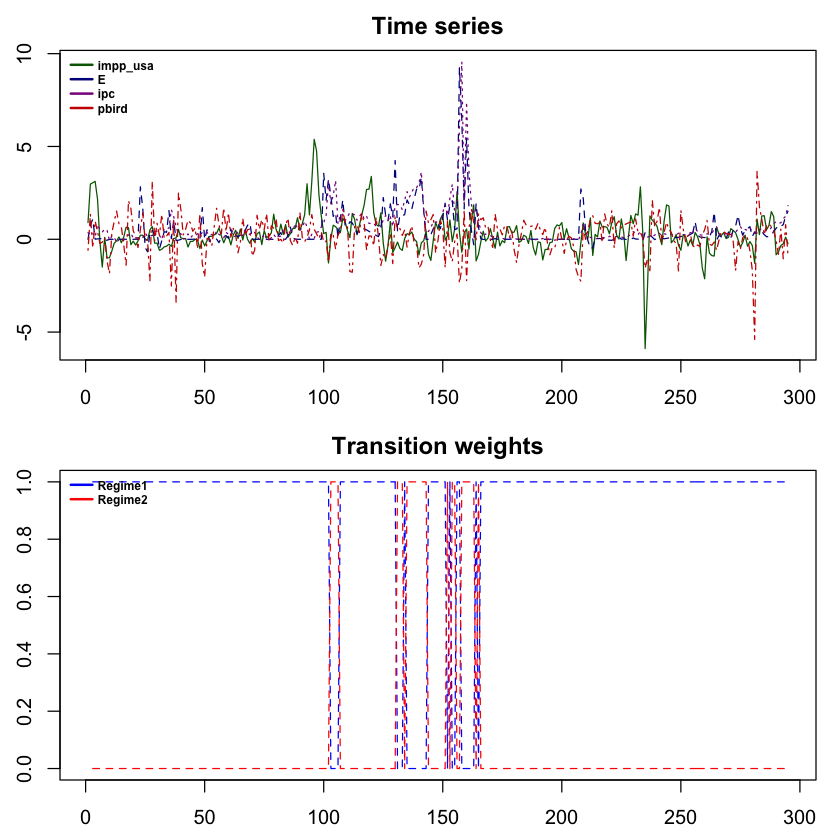

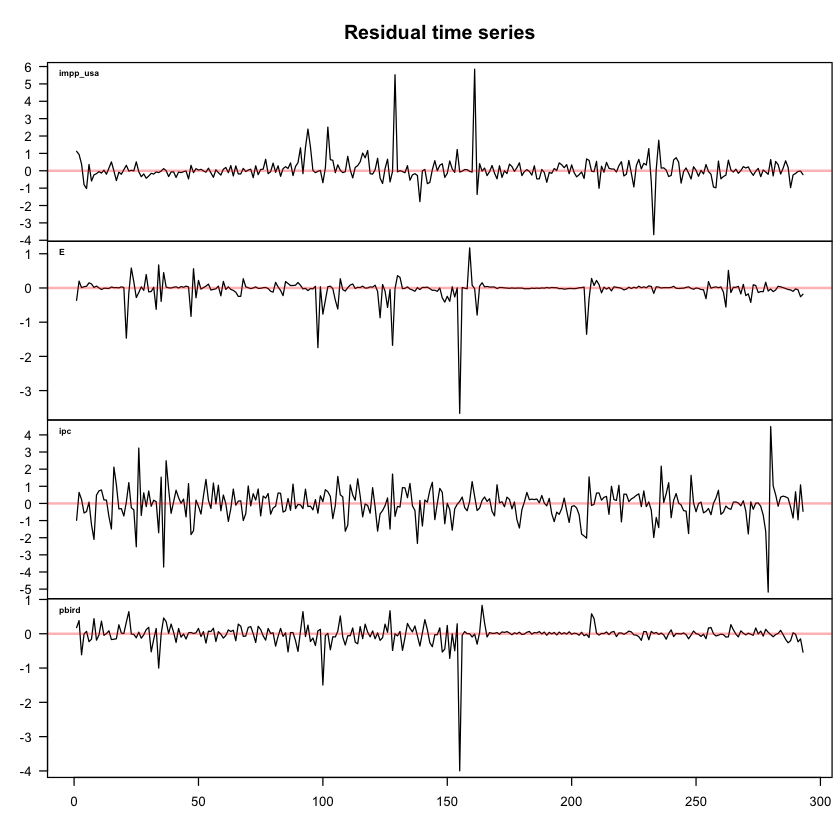

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



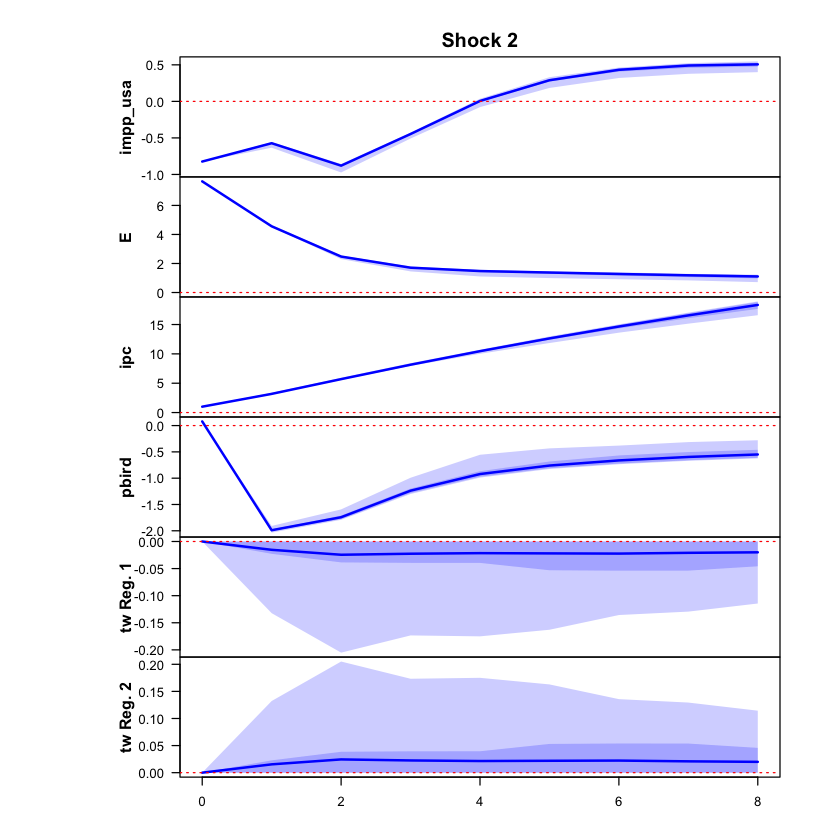

 >>> Linear IRF ( 1  shock units)


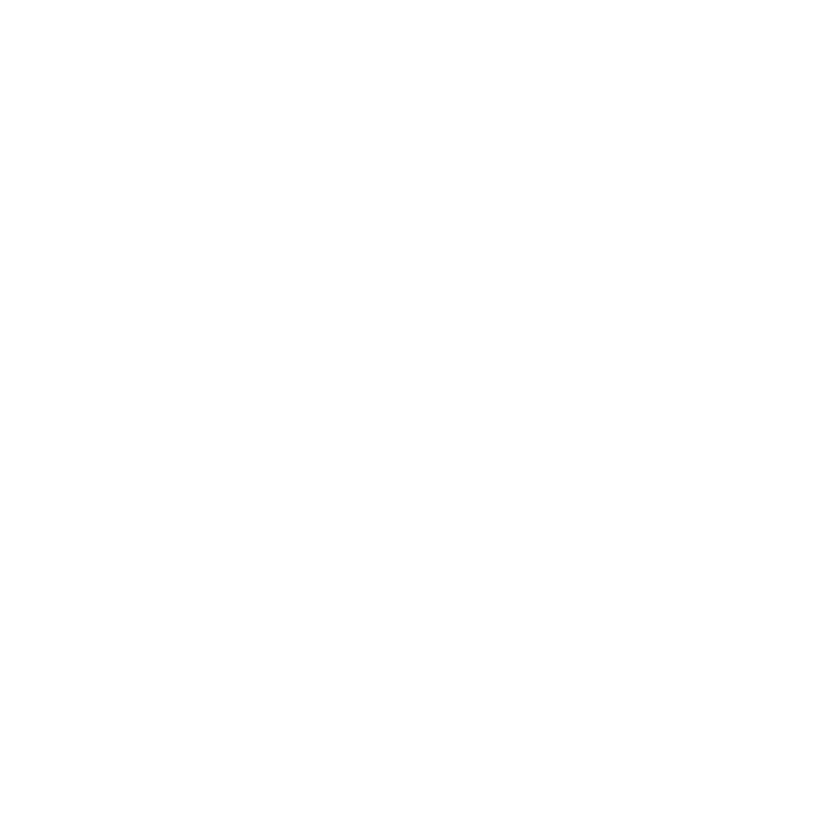

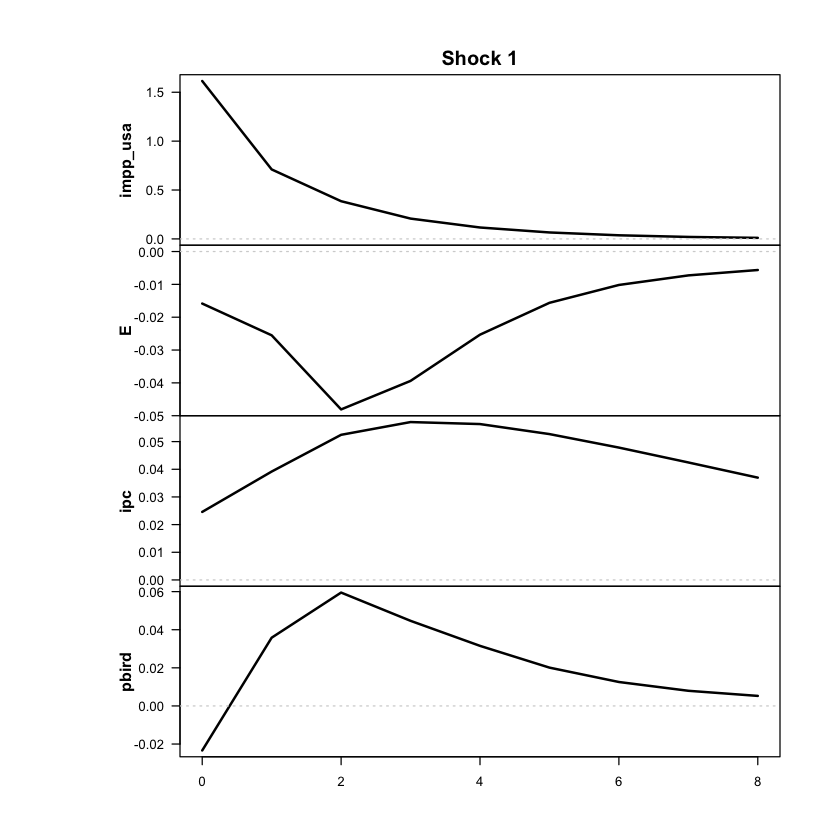

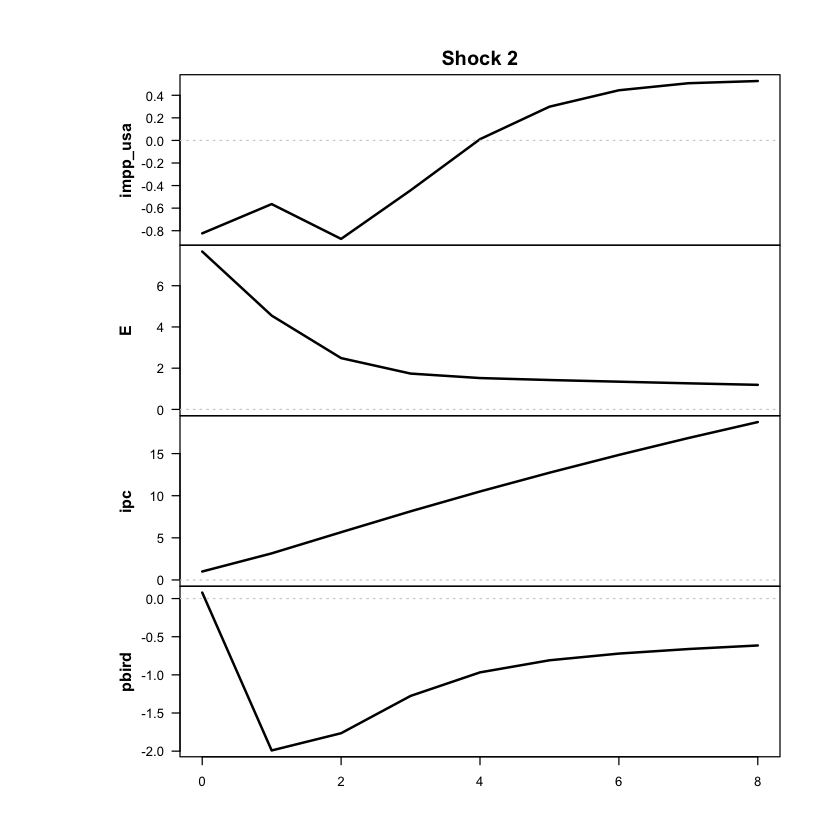

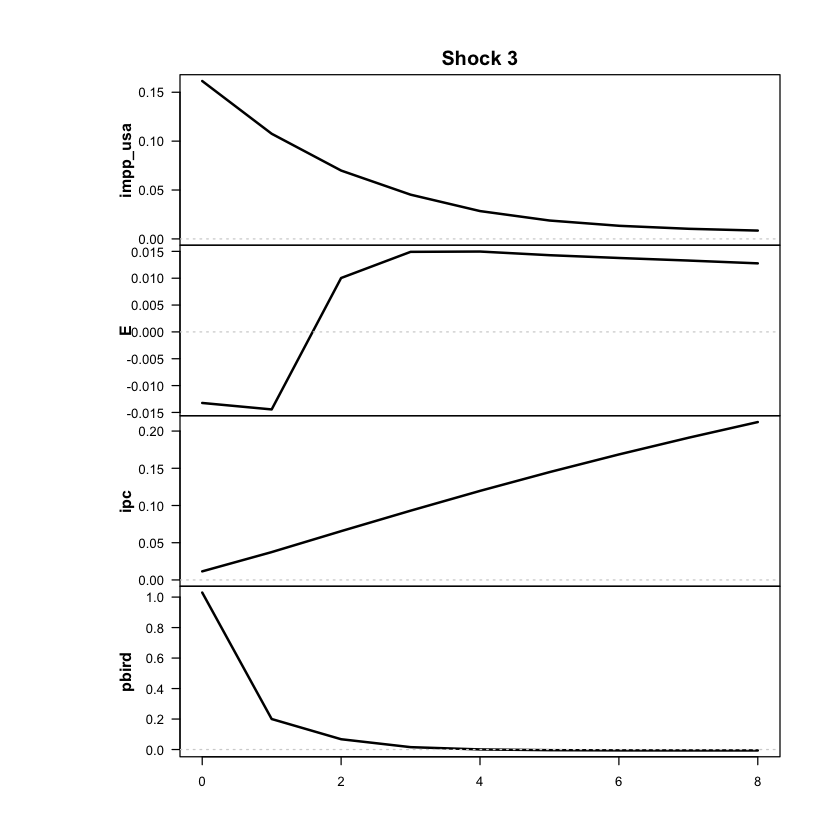

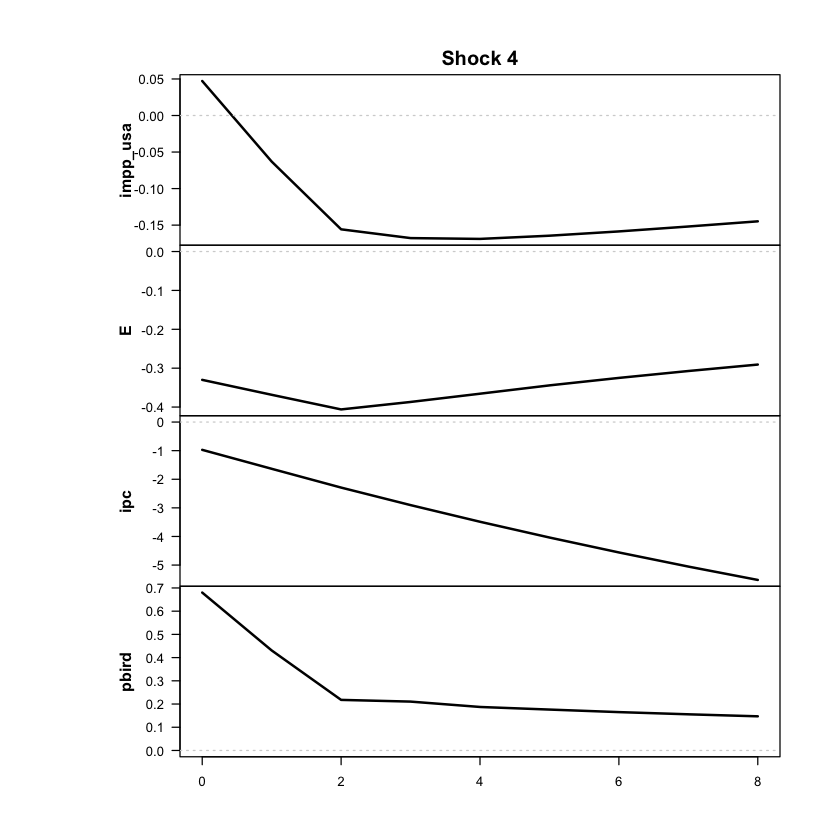

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



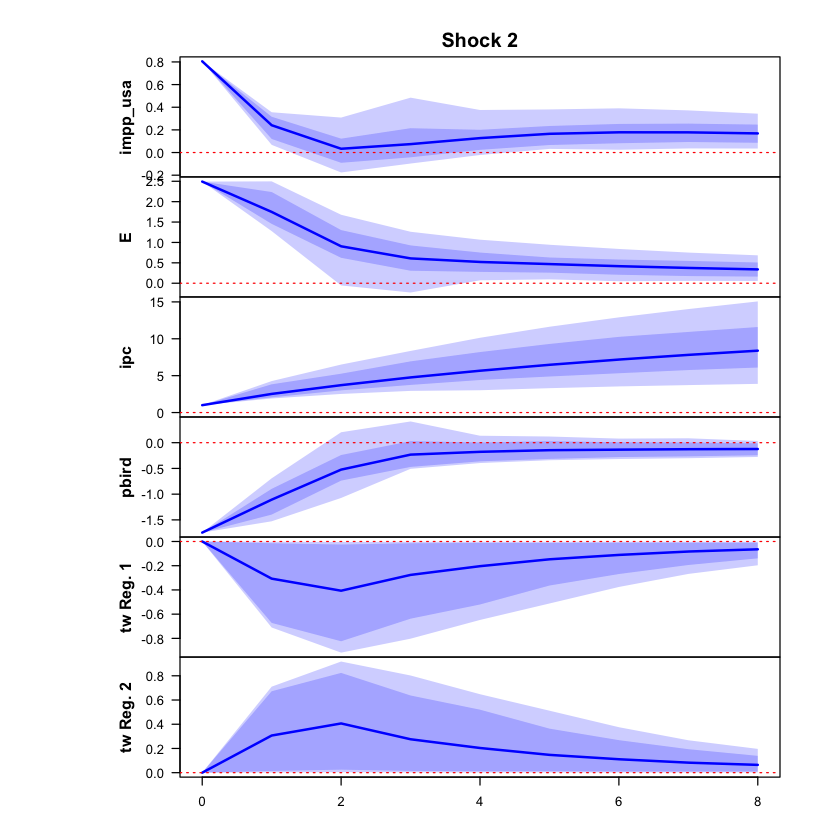

 >>> Linear IRF ( 1  shock units)


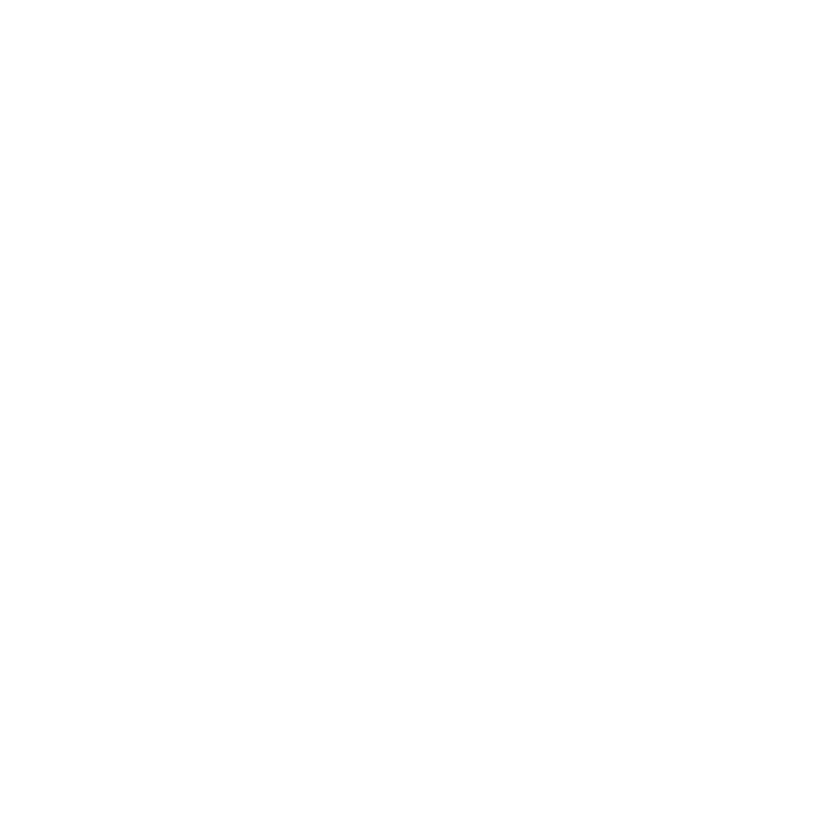

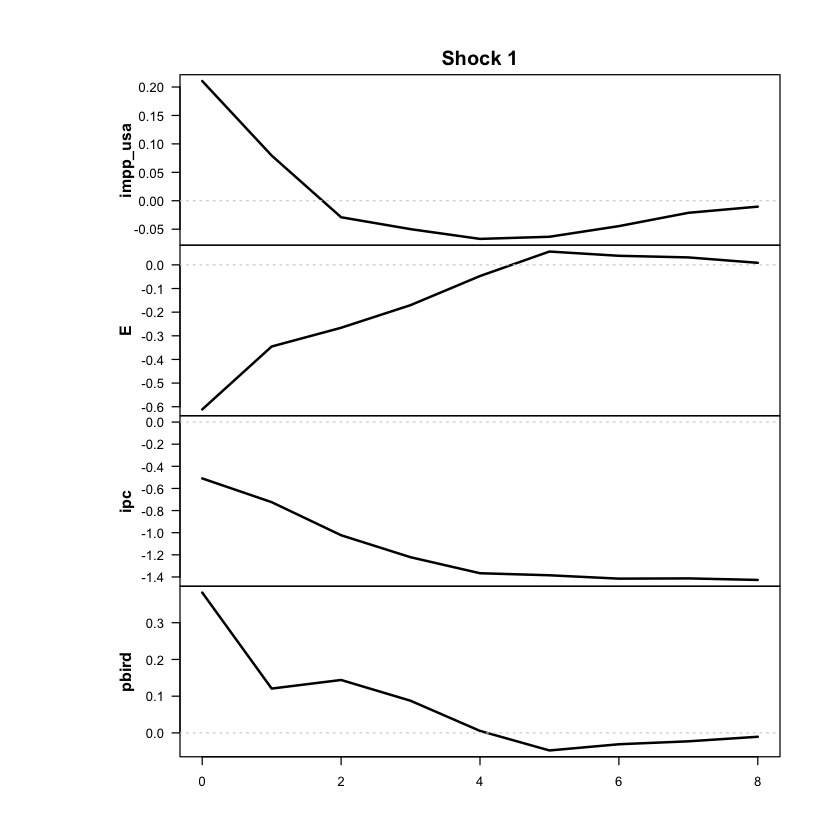

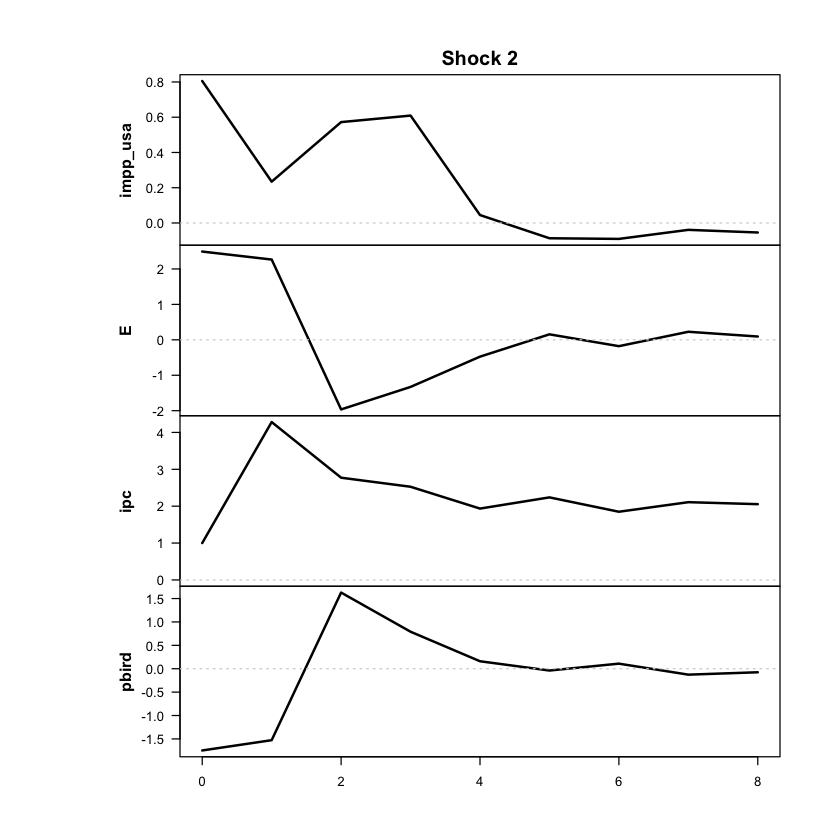

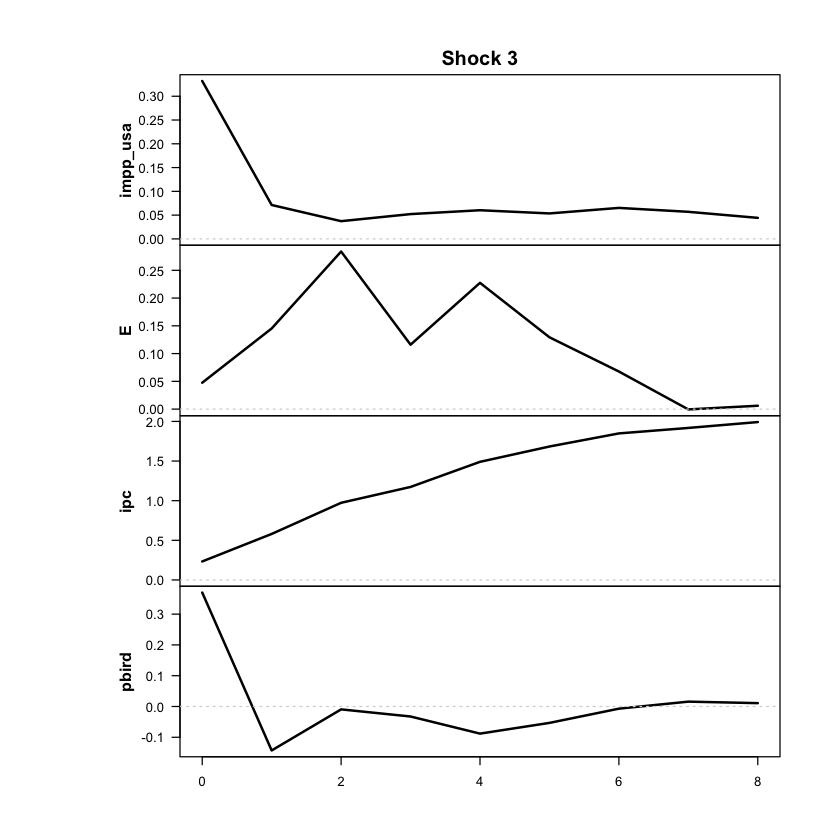

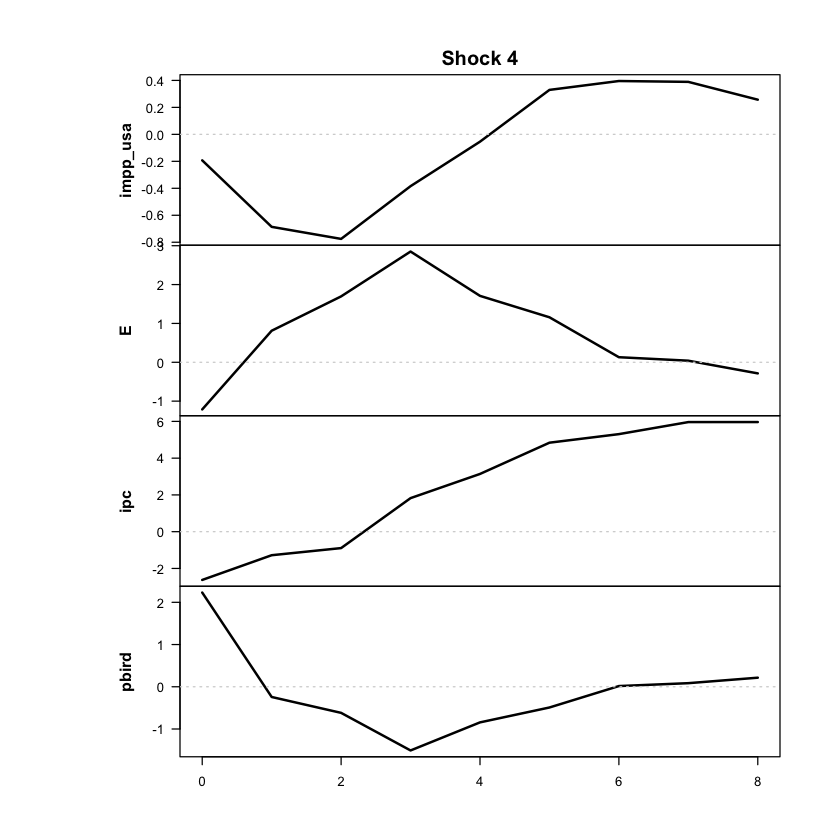

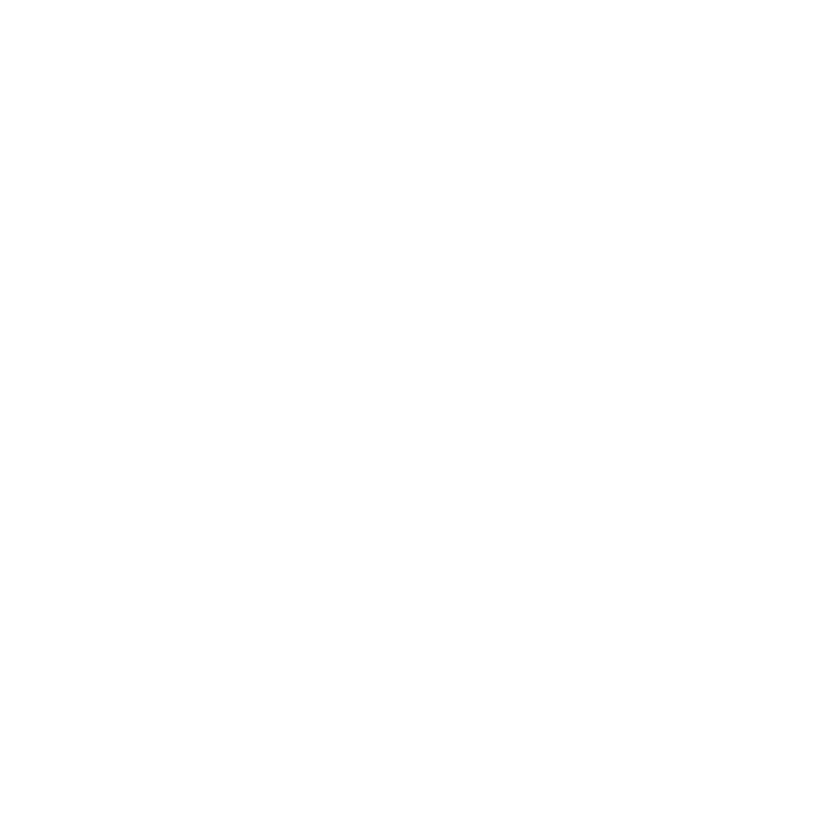

In [ ]:
res <- run_threshold_tvar(
  data = df_ERPT_Arg,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral',
  feature_lag = 2,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc',
  thr_lag = 1,
  shock_var = 'E',
  response_vars = c('ipc'),
  run_tests = FALSE,
  irf_horizons = NULL,
  irf_shocks = 1,
  diagnostic_plots = TRUE,
  nrounds = 500,
  load_presaved = FALSE,
  cond_dist = "ind_Student",       # shocks t de Student independientes
  estim_method = "three-phase"     # recomendado para estos modelos (Virolainen)
)

In [5]:
ic_tvar_indt_p2 <- criterios_info(res, "TVAR-indt p=2")
print(ic_tvar_indt_p2)

         modelo regimenes parametros  loglik    AIC     HQ  BIC
1 TVAR-indt p=2         2        109 -615.43 1448.9 1609.5 1850


In [6]:
resumen_modelo(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"))
# Con ind_Student muestra "errores: ind_Student".

Modelo: threshold | regímenes: 2 | rezagos: 2 | errores: ind_Student 
Umbrales: 37.6% trimestral (258% anualizada) 
Trimestres por régimen (régimen de mayor peso): régimen 1 = 267 | régimen 2 = 26 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      0.79      0.35
E             8.87     52.44
ipc           9.12     67.88
pbird         0.58      0.15


In [7]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -615.43            37.6    NA         NA           267/26
             2 -615.52            37.5    NA         NA           267/26
             3 -615.81            36.6    NA         NA           265/28
             4 -616.30              36    NA         NA           265/28
             5 -616.39            35.3    NA         NA           265/28
             6 -616.43            37.2    NA         NA           266/27
             7 -616.64            36.5    NA         NA           265/28
             8 -616.75            36.4    NA         NA           265/28
             9 -616

In [8]:
print(res$tvar_model)   # avisos y grados de libertad de cada shock (uno por variable)

threshold ind_Student STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 2, M = 2, d = 4, #parameters = 109, #observations = 293 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Degrees of freedom: 2.15, 2.01, 3.05, 2.02 (for all regimes) 
Upper threshold: 1.61 
Regime means: 0.17, 0.06, 0.17, 0.34

   Y      phi0          A1                                 A2                  
1 y1 = [  0.04 ] + [  0.44 -0.04  0.12  0.03 ] y1.1 + [  0.04 -0.09  0.11  0.00
2 y2   [ -0.02 ]   [ -0.01  0.57  0.18 -0.01 ] y2.1   [ -0.02 -0.08  0.12  0.02
3 y3   [  0.01 ]   [  0.00  0.20  0.63  0.02 ] y3.1   [  0.00  0.01  0.18  0.01
4 y4   [  0.29 ]   [  0.03 -0.23 -0.23  0.19 ] y4.1   [  0.02  0.01  0.12  0.02
                 B                         
1 ] y1.2 + [  1.61  0.21  0.16  0.05 ] eps1
2 ] y2.2   [ -0.02 -2.00 -0.01 -0.33 ] eps2
3 ] y3.2   [  0.02 -0.26  0.01 -0.97 ] eps3
4 ] y4.2   [ -0.02 -0.02  1.03  0.68 ] eps4

Regime 2 
Regime means: -0.02,  0.93,  1.32, 

In [38]:
shock_tvar_indt_p2 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Revisar que el MISMO shock concentre el efecto sobre E en los dos regímenes.
# Si aparece el aviso "!!! ATENCIÓN", no seguir: hay que reordenar las columnas de B.
shock_tvar_indt_p2

Efecto de impacto de cada shock (régimen 1) (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0446  0.0059  0.0045  0.0013
  E        -0.0038 -0.4774 -0.0032 -0.0790
  ipc       0.0049 -0.0517  0.0023 -0.1929
  pbird    -0.0006 -0.0006  0.0286  0.0189

Participación de E en el efecto de cada shock (régimen 1) :
shock_1 shock_2 shock_3 shock_4 
   0.01    0.99    0.01    0.27 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
 -1.288   0.108  -0.723   2.443 

--- Régimen 2 ---
Efecto de impacto (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0058 -0.0216  0.0092 -0.0053
  E        -0.1463 -0.5808  0.0114 -0.2903
  ipc      -0.1011 -0.1934  0.0463 -0.5214
  pbird     0.0106  0.0472  0.0103  0.0619
Participación de E :
shock_1 shock_2 shock_3 shock_4 
   0.67    0.75    0.09    0.33 
ERPT de impacto:
shock_1 shock_2 shock_3 shock_4 
  0.691   0.333   4.072   1.796 

El mism

[1] 2

### ERPT — TVAR con shocks t independientes (solo si pasó el diagnóstico)

In [10]:
out_impp_usa_tvar_indt_p2 <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar_indt_p2)

Shock: 1.000 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 61.2%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 267 | régimen 2 = 26 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

Promedio entre trimestres:
  horizonte reg_bajo_original reg_alto_original
1         0            0.1084            0.3330
2         1            0.3828            1.4035
3         2            0.6640            1.0265
4         3            0.9066            0.9348
5         4            1.1295            0.8083
6         5            1.3338            0.7472
7         6            1.5159            0.6699
8         7            1.6796            0.6195
9         8            1.8277            0.5640

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.1084           0.3330
2         1           0.3453           1.4264
3         2           0.6179           0.9568
4         3           0.8752           0.8640
5         4        

In [11]:
out_impp_usa_tvar_indt_p2_acum <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar_indt_p2,
                      definicion = "acumulado")

Shock: 1.000 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 61.2%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 267 | régimen 2 = 26 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

Promedio entre trimestres:
  horizonte reg_bajo_original reg_alto_original
1         0            0.1084            0.3330
2         1            0.2331            0.7272
3         2            0.3393            0.8133
4         3            0.4204            1.1974
5         4            0.4844            1.2683
6         5            0.5329            1.0688
7         6            0.5707            1.1043
8         7            0.5988            1.1062
9         8            0.6155            1.0627

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.1084           0.3330
2         1           0.2163           0.7459
3         2           0.3226           0.8264
4         3           0.4110           1.1579
5         4        

In [12]:
   out_impp_usa_tvar_indt_p2_d8 <- erpt_historia(res, data = df_ERPT_Arg,
                                                 endog = c("impp_usa", "E", "ipc", "pbird"),
                                                 shock_num = shock_tvar_indt_p2, deprec_pct = 8)

Shock: 0.161 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 8.0%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 267 | régimen 2 = 26 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

Promedio entre trimestres:
  horizonte reg_bajo_original reg_alto_original
1         0            0.1084            0.3330
2         1            0.3531            1.2672
3         2            0.6243            1.2584
4         3            0.8854            1.3397
5         4            1.1254            1.3613
6         5            1.3446            1.4063
7         6            1.5506            1.4164
8         7            1.7388            1.4327
9         8            1.9214            1.4439

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.1084           0.3330
2         1           0.3459           1.4037
3         2           0.6224           1.0865
4         3           0.8940           1.0770
5         4        

In [13]:
   out_impp_usa_tvar_indt_p2_d8_acum <- erpt_historia(res, data = df_ERPT_Arg,
                                                      endog = c("impp_usa", "E", "ipc", "pbird"),
                                                      shock_num = shock_tvar_indt_p2, deprec_pct = 8,
                                                      definicion = "acumulado")

Shock: 0.161 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 8.0%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 267 | régimen 2 = 26 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

Promedio entre trimestres:
  horizonte reg_bajo_original reg_alto_original
1         0            0.1084            0.3330
2         1            0.2194            0.6631
3         2            0.3241            0.7612
4         3            0.4127            1.0090
5         4            0.4828            1.0292
6         5            0.5357            1.0957
7         6            0.5764            1.1200
8         7            0.5067            1.1256
9         8            0.6759            1.0896

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.1084           0.3330
2         1           0.2166           0.7173
3         2           0.3226           0.8063
4         3           0.4143           0.9688
5         4        

In [14]:
   out_impp_usa_tvar_indt_p2_d8_acum_s456 <- erpt_historia(res, data = df_ERPT_Arg,
                       endog = c("impp_usa", "E", "ipc", "pbird"),
                       shock_num = shock_tvar_indt_p2, deprec_pct = 8,
                       definicion = "acumulado", semilla = 456)

Shock: 0.161 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 8.0%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 267 | régimen 2 = 26 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

Promedio entre trimestres:
  horizonte reg_bajo_original reg_alto_original
1         0            0.1084            0.3330
2         1            0.2188            0.6696
3         2            0.3215            0.7737
4         3            0.4090            0.9840
5         4            0.4771            1.1161
6         5            0.5293            1.1603
7         6            0.5672            1.2031
8         7            0.5825            1.2169
9         8            0.7189            1.2253

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.1084           0.3330
2         1           0.2156           0.7398
3         2           0.3203           0.8261
4         3           0.4117           1.0043
5         4        

In [15]:
o <- out_impp_usa_tvar_indt_p2_d8_acum
round(data.frame(
  horizonte      = 0:8,
  bajo_promedio  = rowMeans(o$erpt[, o$alpha < 0.1]),
  bajo_mediana   = apply(o$erpt[, o$alpha < 0.1], 1, median),
  alto_promedio  = rowMeans(o$erpt[, o$alpha > 0.9]),
  alto_mediana   = apply(o$erpt[, o$alpha > 0.9], 1, median)), 3)

,horizonte,bajo_promedio,bajo_mediana,alto_promedio,alto_mediana
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0,0,0.108,0.108,0.333,0.333
1,1,0.219,0.217,0.663,0.717
2,2,0.324,0.323,0.761,0.806
3,3,0.413,0.414,1.009,0.969
4,4,0.483,0.487,1.029,1.024
5,5,0.536,0.544,1.096,1.062
6,6,0.576,0.592,1.120,1.093
7,7,0.507,0.630,1.126,1.101
8,8,0.676,0.666,1.090,1.052


In [ ]:
# Lo comento porque hace 5000 simulaciones, y tarda mucho. Está corrido sin mediana. 
#   out_impp_usa_tvar_indt_p2_d8_acum_R5000 <- erpt_historia(res, data = df_ERPT_Arg,
                       endog = c("impp_usa", "E", "ipc", "pbird"),
                       shock_num = shock_tvar_indt_p2, deprec_pct = 8,
                       definicion = "acumulado", R1 = 5000)

Shock: 0.161 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 8.0%.

Estimando 293 GIRFs (una por trimestre), 5000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 5000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 267 | régimen 2 = 26 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

  horizonte reg_bajo_original reg_alto_original
1         0            0.1084            0.3330
2         1            0.2204            0.6667
3         2            0.3265            0.7655
4         3            0.4142            1.1183
5         4            0.4835            1.0523
6         5            0.5360            1.0894
7         6            0.5737            1.1092
8         7            0.4983            1.1136
9         8            0.6847            1.1064


In [16]:
out_impp_usa_tvar_indt_p2_d8 <- erpt_historia(res, data = df_ERPT_Arg,
                                                 endog = c("impp_usa", "E", "ipc", "pbird"),
                                                 shock_num = shock_tvar_indt_p2, deprec_pct = 1)

Shock: 0.021 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 1.0%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 267 | régimen 2 = 26 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

Promedio entre trimestres:
  horizonte reg_bajo_original reg_alto_original
1         0            0.1084            0.3330
2         1            0.3045            0.9476
3         2            0.6106            2.0776
4         3            0.9209            2.7421
5         4            1.2105            3.2809
6         5            1.4742            3.6747
7         6            1.7586            3.9800
8         7            2.0110            4.2238
9         8            2.3009            4.3687

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.1084           0.3330
2         1           0.3468           1.1668
3         2           0.6729           1.9595
4         3           0.9978           2.6147
5         4        

In [17]:
   out_impp_usa_tvar_indt_p2_d8_acum <- erpt_historia(res, data = df_ERPT_Arg,
                                                      endog = c("impp_usa", "E", "ipc", "pbird"),
                                                      shock_num = shock_tvar_indt_p2, deprec_pct = 1,
                                                      definicion = "acumulado")

Shock: 0.021 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 1.0%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 267 | régimen 2 = 26 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

Promedio entre trimestres:
  horizonte reg_bajo_original reg_alto_original
1         0            0.1084            0.3330
2         1            0.1910            0.4834
3         2            0.3117            0.6868
4         3            0.4112            0.8248
5         4            0.5433            0.9763
6         5            0.5421            1.0531
7         6            0.6091            1.3480
8         7            0.6331            2.6182
9         8            0.8475            1.2760

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.1084           0.3330
2         1           0.2171           0.5759
3         2           0.3360           0.7302
4         3           0.4350           0.8069
5         4        

Shock: 0.161 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 8.0%.

   régimen 1: el mismo shock mueve E en +8.0% en el impacto

   régimen 2: el mismo shock mueve E en +9.8% en el impacto

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   pbird
         0 0.1084  0.0012
         1 0.3465 -0.0287
         2 0.6146 -0.0542
         3 0.8719 -0.0716
         4 1.1107 -0.0842
         5 1.3318 -0.0944
         6 1.5424 -0.1040
         7 1.7356 -0.1122
         8 1.9169 -0.1195

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   pbird
         0 0.3330 -0.0813
         1 1.1423 -0.1422
         2 1.1554 -0.1146
         3 1.2502 -0.0929
         4 1.3172 -0.0896
         5 1.3821 -0.0865
         6 1.4326 -0.0861
         7 1.4869 -0.0871
         8 1.5329 -0.0882


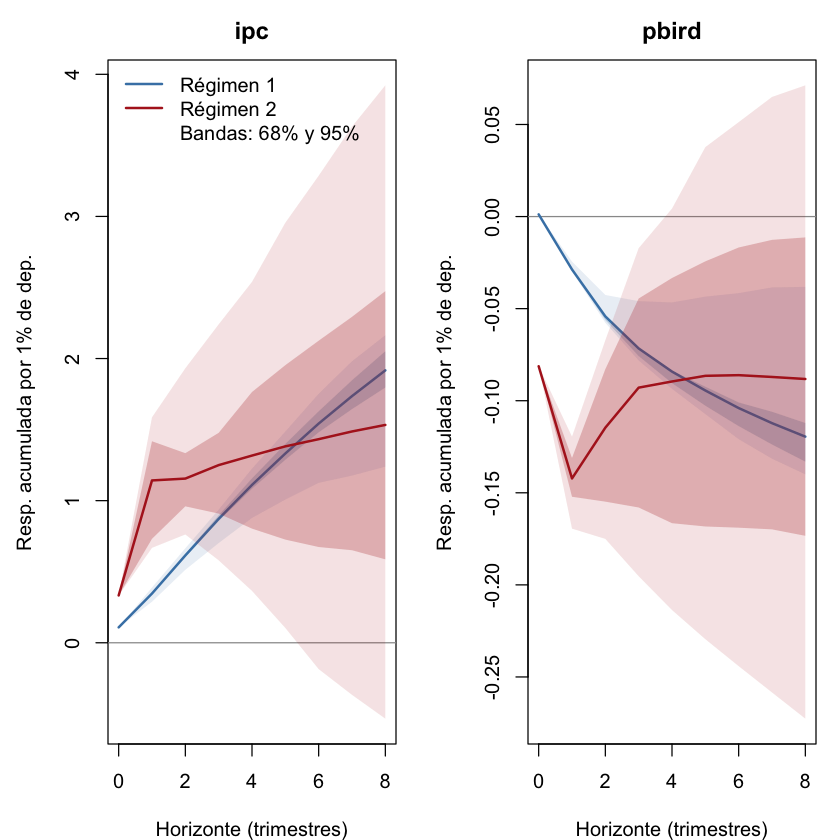

In [39]:
# GIRF con el shock de 8% (rehacer)
graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"),
                       shock_num = shock_tvar_indt_p2, deprec_pct = 8,
                       archivo = "girf_original_impp_usa_tvar_indt_p2_sincap")

In [40]:
ls(pattern = "^out_")

[1] "out_impp_usa_tvar_indt_p2"             
[2] "out_impp_usa_tvar_indt_p2_acum"        
[3] "out_impp_usa_tvar_indt_p2_d8"          
[4] "out_impp_usa_tvar_indt_p2_d8_acum"     
[5] "out_impp_usa_tvar_indt_p2_d8_acum_s456"

In [ ]:
# ERPT para gráficos: mediana como referencia (sin acotar: en TVAR-indt no hay valores absurdos)
g_indt      <- graficos_con_mediana(out_impp_usa_tvar_indt_p2)
g_indt_acum <- graficos_con_mediana(out_impp_usa_tvar_indt_p2_acum)

Gráficos con la MEDIANA por régimen como referencia.
Gráficos con la MEDIANA por régimen como referencia.


In [47]:
out_impp_usa_tvar_indt_p2_acum$chequeo_mediana

horizonte,reg_bajo_mediana,reg_alto_mediana
<int>,<dbl>,<dbl>
0,0.1083799,0.3330145
1,0.2162683,0.7459263
2,0.3226206,0.8264426
3,0.4109842,1.1578873
4,0.4823014,1.2008795
5,0.5388227,1.0800702
6,0.5854798,1.0111748
7,0.6236898,1.0292528
8,0.6558802,1.0535367


Mediana de ERPT (transmisión) por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_mediana reg_alto_mediana
         4            0.482            1.201
Mediana de ERPT (relativo al shock) por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_mediana reg_alto_mediana
         4            1.113            0.756


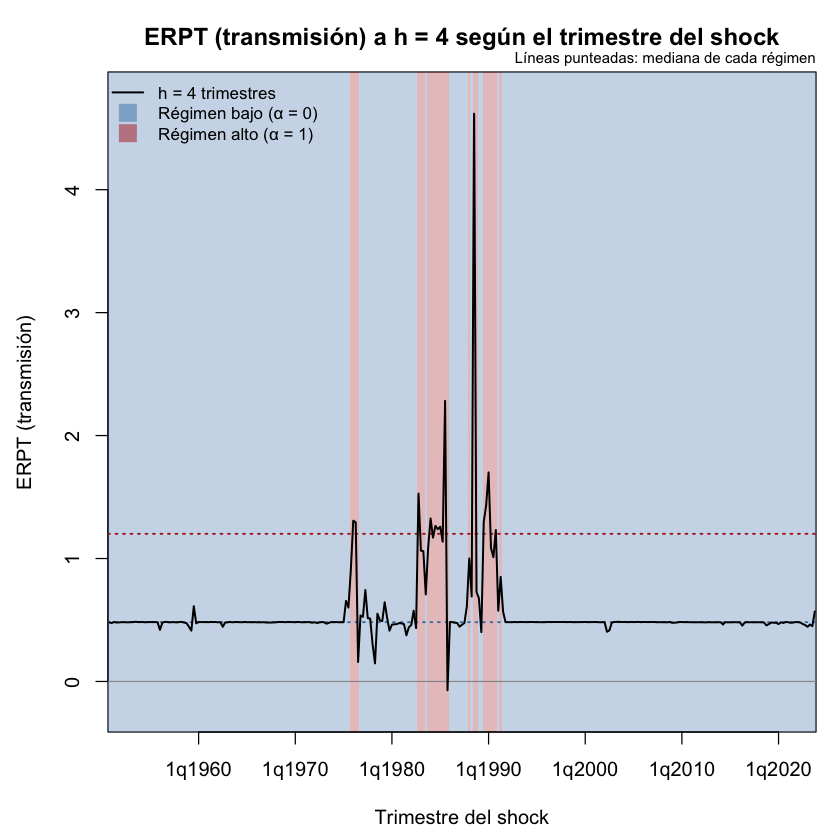

Mediana de ERPT (transmisión) por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_mediana reg_alto_mediana
         8            0.656            1.054


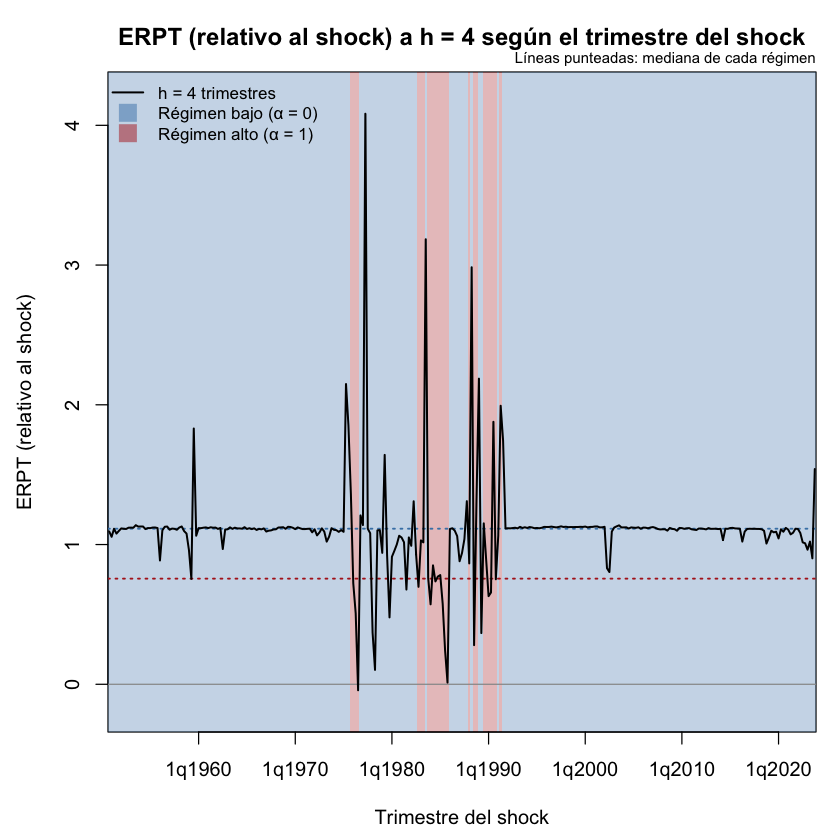

Mediana de ERPT (relativo al shock) por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_mediana reg_alto_mediana
         8             1.92            0.701


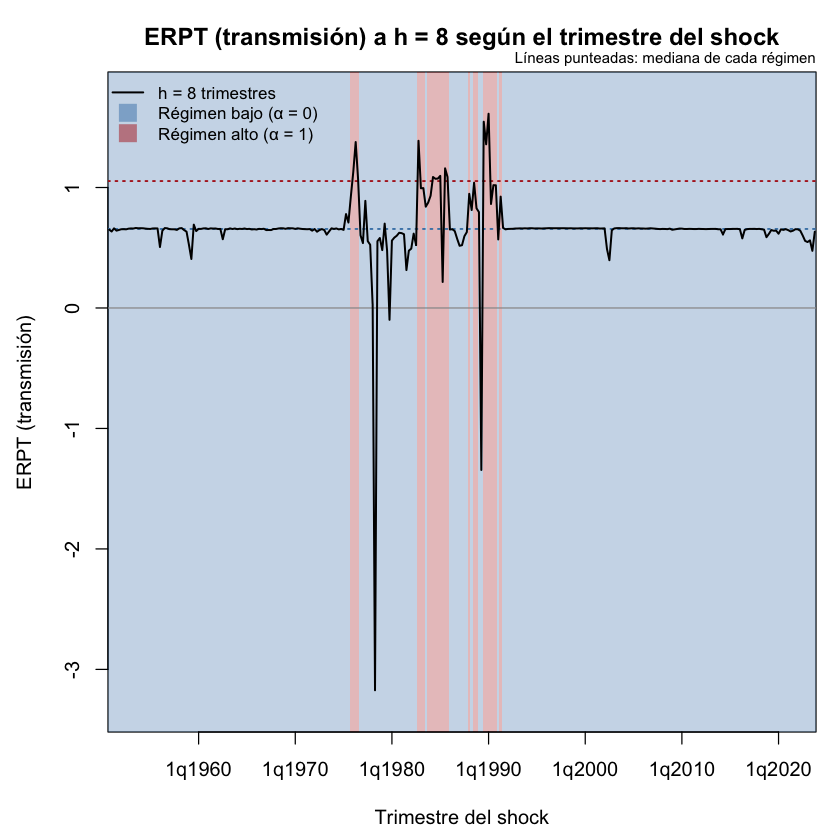

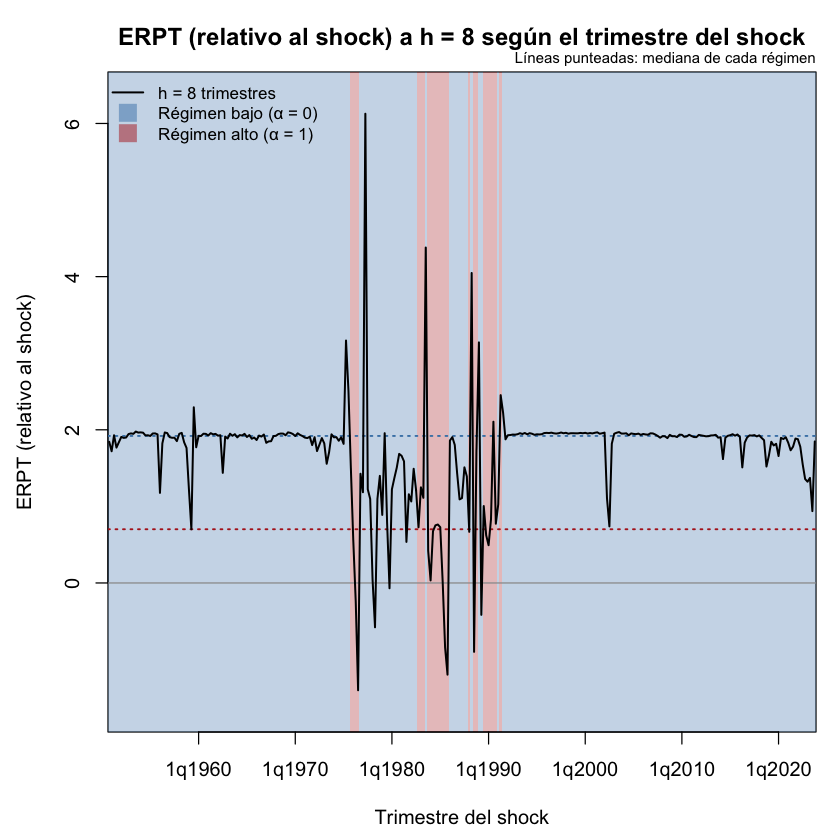

In [48]:
for (h in c(4, 8)) {
  graficar_erpt_2d_bandas(g_indt_acum, horizontes = h, eje_y = "ERPT (transmisión)",
      archivo = paste0("erpt_2d_bandas_impp_usa_tvar_indt_p2_acum_h", h, "_sincap"))
  graficar_erpt_2d_bandas(g_indt, horizontes = h, eje_y = "ERPT (relativo al shock)",
      archivo = paste0("erpt_2d_bandas_impp_usa_tvar_indt_p2_h", h, "_sincap"))
}

In [49]:
   out_impp_usa_tvar_indt_p2$chequeo_mediana

horizonte,reg_bajo_mediana,reg_alto_mediana
<int>,<dbl>,<dbl>
0,0.1083799,0.3330145
1,0.3452734,1.4264110
2,0.6179266,0.9568246
3,0.8751743,0.8639619
4,1.1133862,0.7559871
5,1.3380279,0.7480916
6,1.5483439,0.7220152
7,1.7411770,0.7205646
8,1.9196911,0.7014439


Umbrales (inflación trimestral de t-1): 37.6% trimestral (258% anualizada) 
Trimestres por régimen: régimen 1 = 267 | régimen 2 = 26 


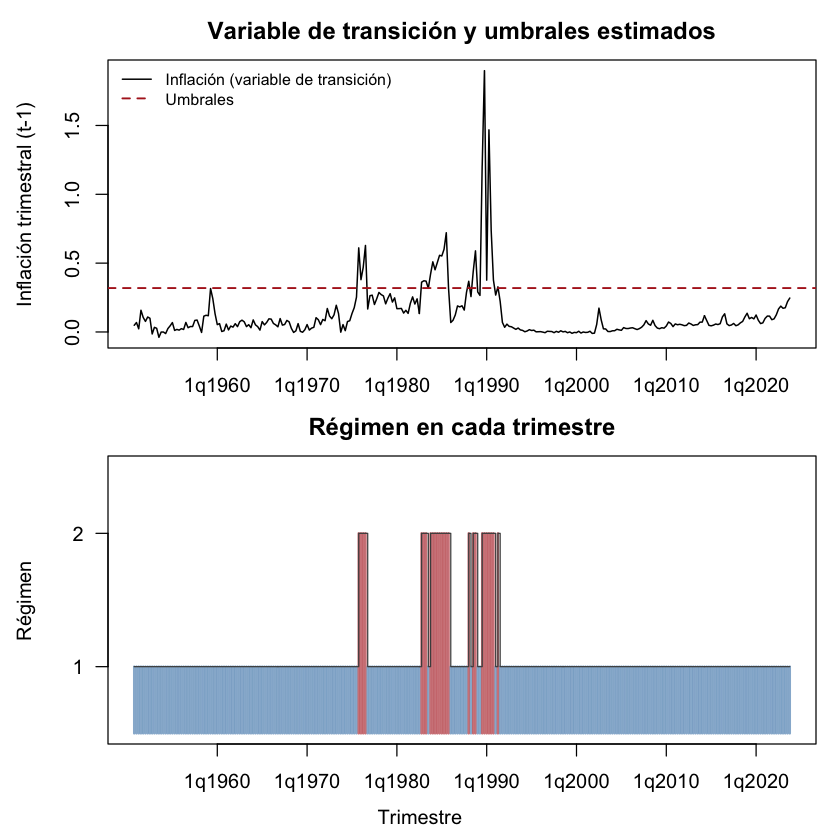

In [43]:
graficar_transicion(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_tvar_indt_p2_sincap")

Shock: 1.000 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 61.2%.

   régimen 1: el mismo shock mueve E en +61.2% en el impacto

   régimen 2: el mismo shock mueve E en +78.7% en el impacto

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   pbird
         0 0.1084  0.0012
         1 0.3766 -0.0294
         2 0.6562 -0.0519
         3 0.8984 -0.0647
         4 1.1203 -0.0741
         5 1.3210 -0.0820
         6 1.5008 -0.0885
         7 1.6624 -0.0942
         8 1.8104 -0.0994

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   pbird
         0 0.3330 -0.0813
         1 1.3500 -0.1496
         2 0.9881 -0.0826
         3 0.8724 -0.0308
         4 0.7254 -0.0169
         5 0.6128 -0.0068
         6 0.5051 -0.0018
         7 0.4149  0.0019
         8 0.3298  0.0050


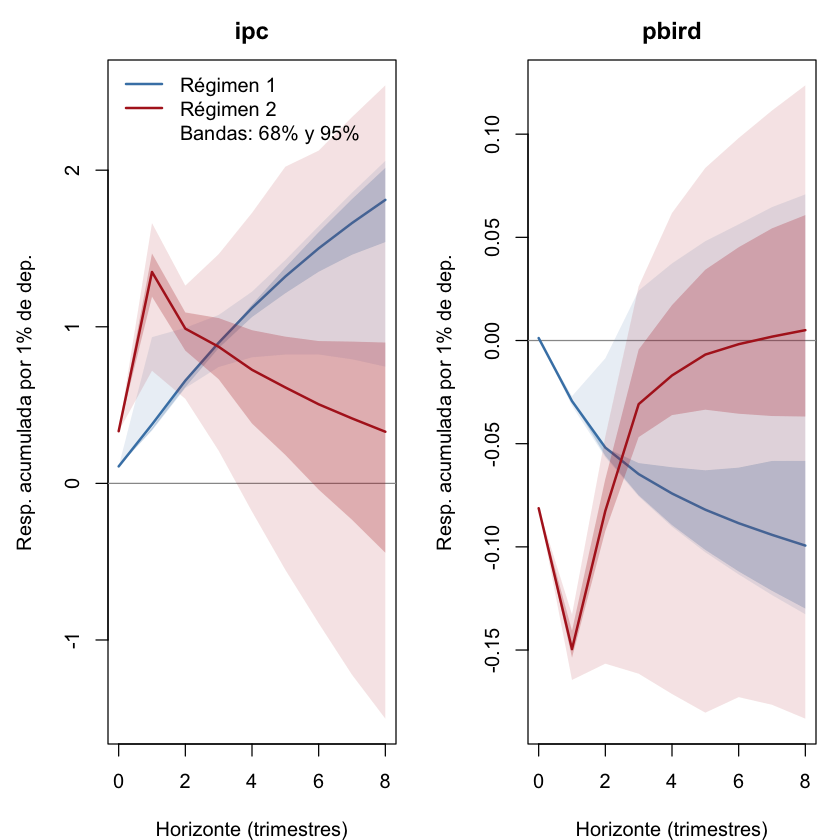

In [50]:
#GIRF con shock de 1 desvío (61% de depreciación): sensibilidad al tamaño del shock
graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar_indt_p2,
                       archivo = "girf_original_impp_usa_tvar_indt_p2_1desvio_sincap")

## VLSTAR, 2 regímenes, p = 2, shocks t independientes

Desvíos usados para escalar:
  impp_usa          E        ipc      pbird 
0.02758807 0.23928824 0.19858620 0.02774553 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating the AR and weight parameters by nonlinear least squares for 10000 vectors of weight parameters...

PHASE 2: Estimating the error distribution parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -855.741

The largest loglik: -739.162

PHASE 3: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -655.517

The largest loglik: -523.689

Filtering inappropriate estimates...

Filtered through 1 inappropriate (or unstable) estimates with a larger (penalized) log-likelihood

Calculating approximate standard errors...

Finished!




========= Unstructured fitted model ==========
========= Structured fitted model (non-Gaussianity) ==========
Saving trained models to models/ folder

 >>> DIAGNOSTIC PLOTS


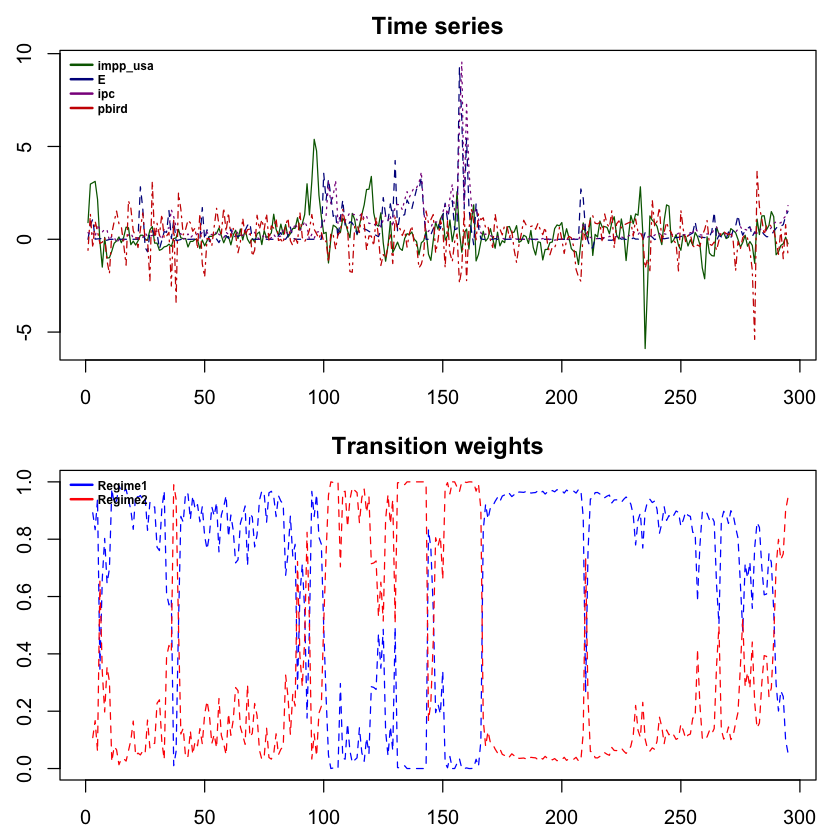

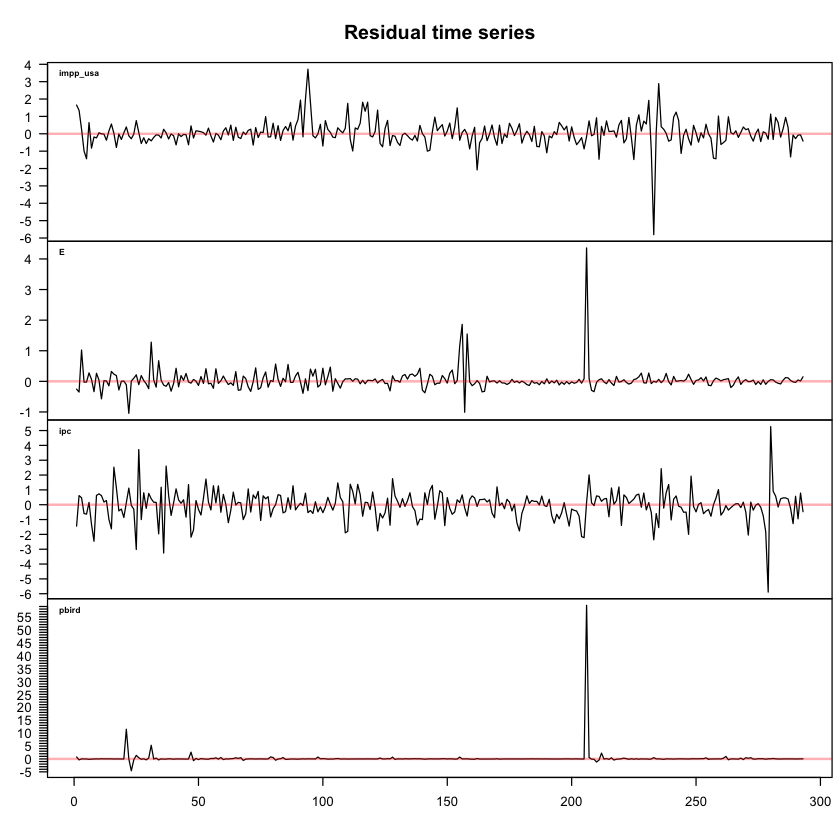

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



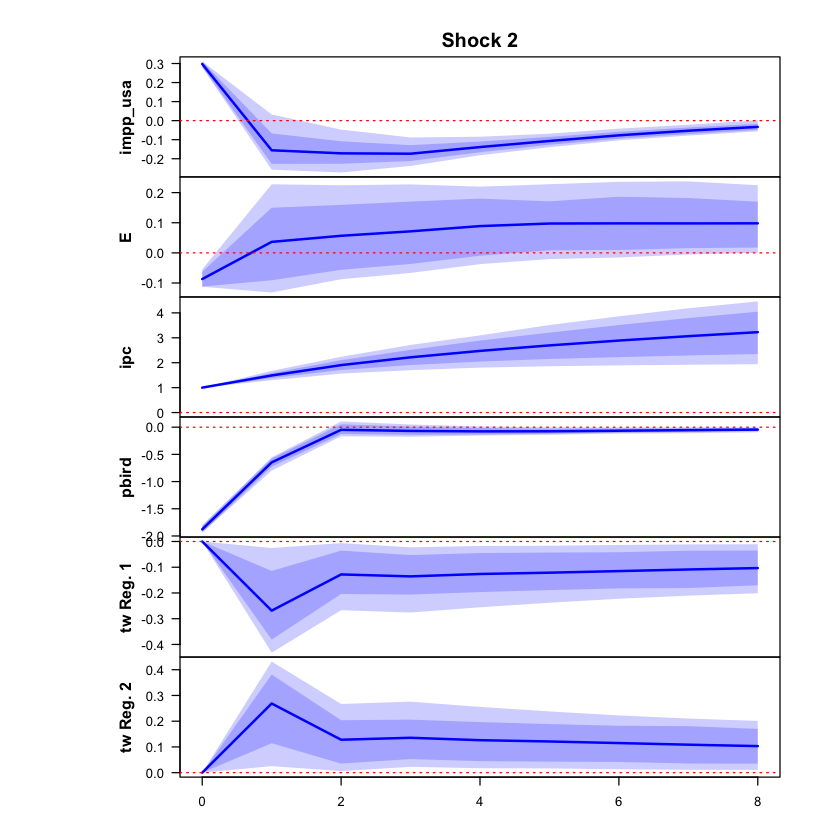

 >>> Linear IRF ( 1  shock units)


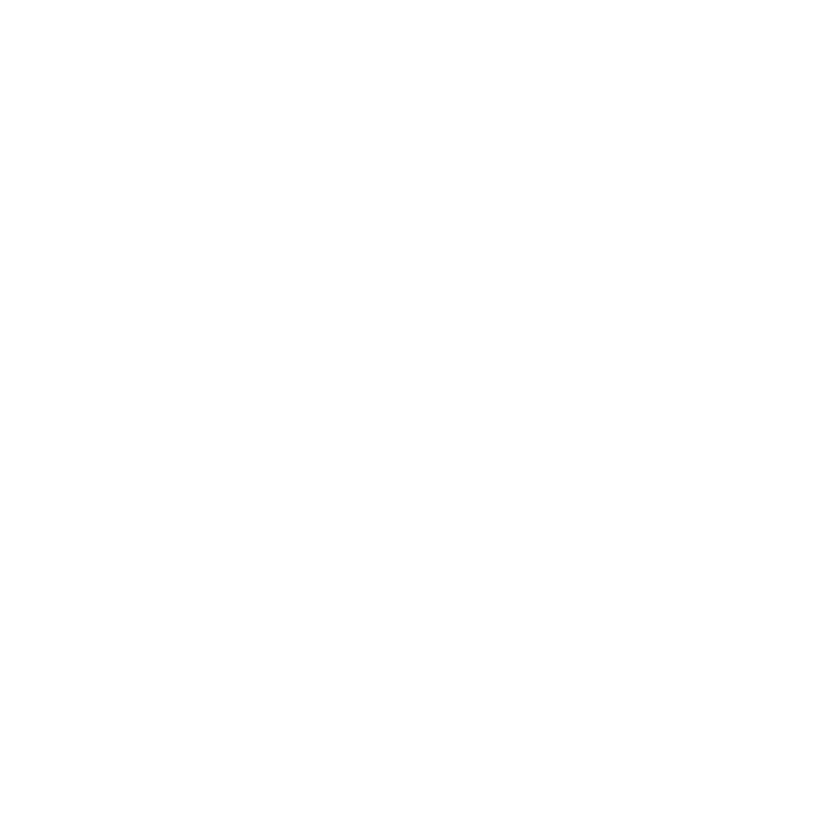

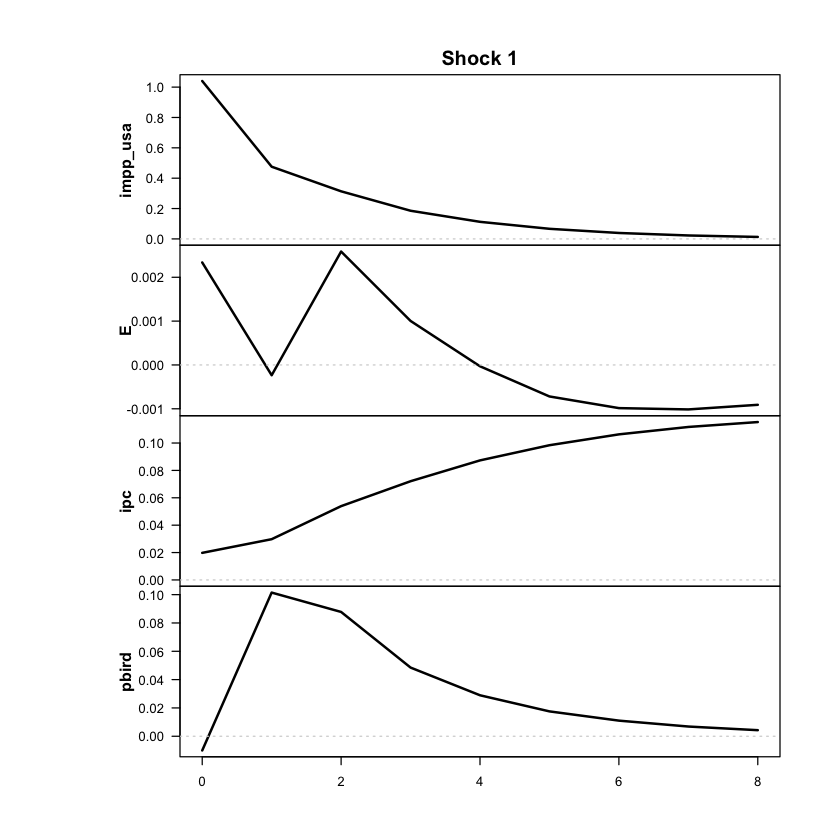

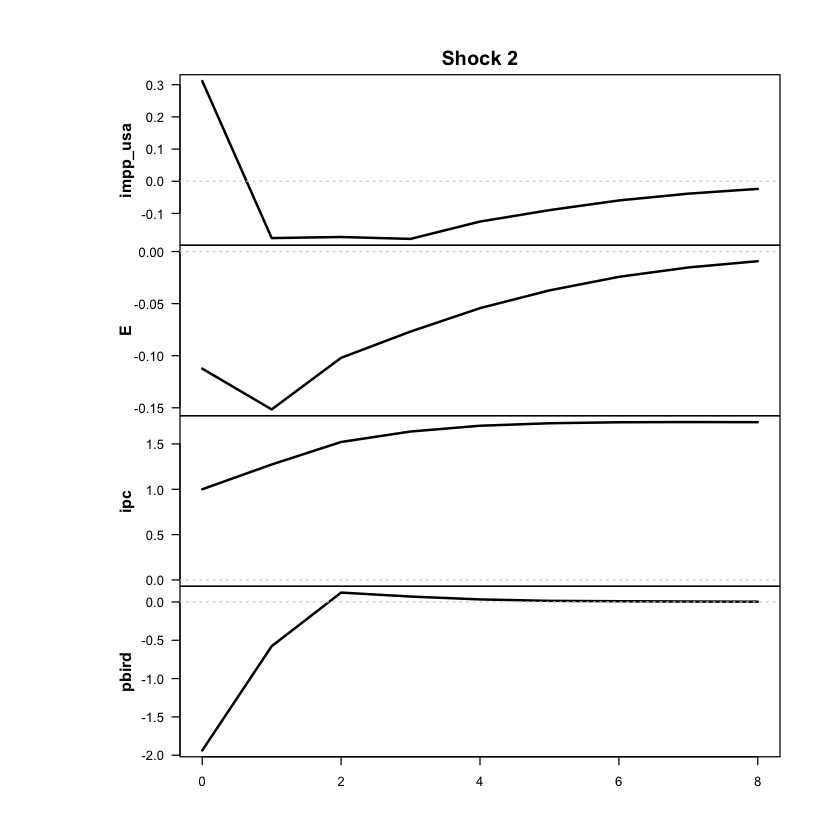

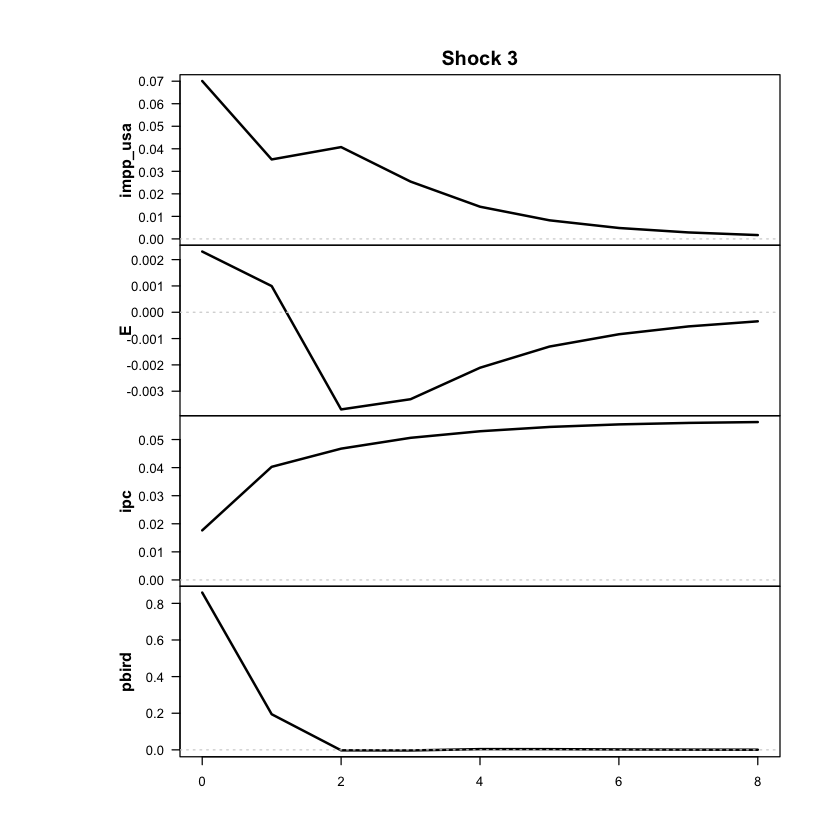

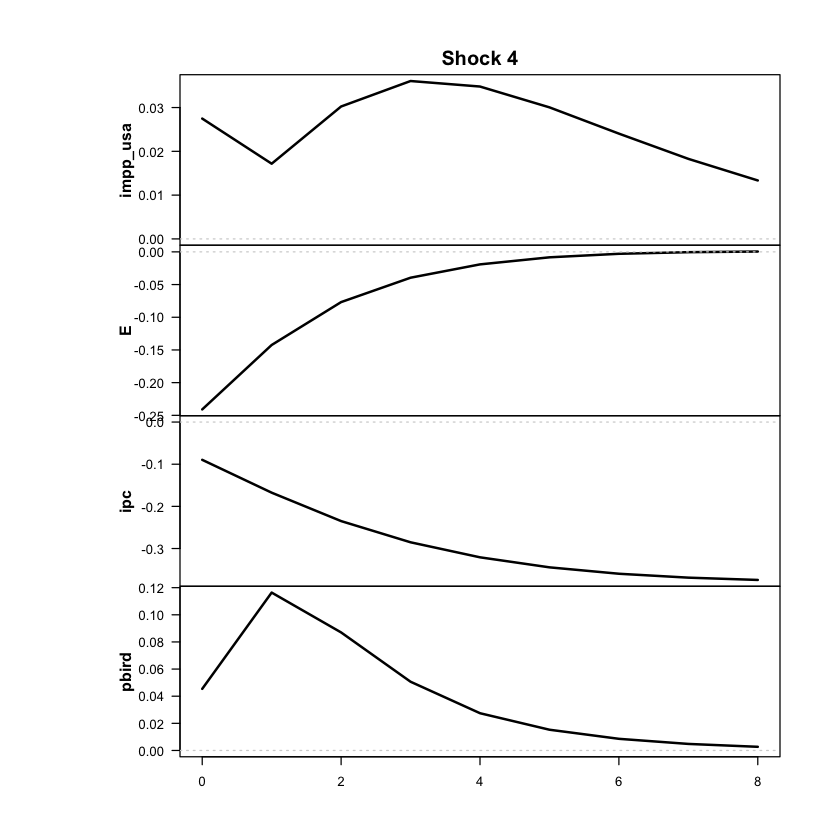

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



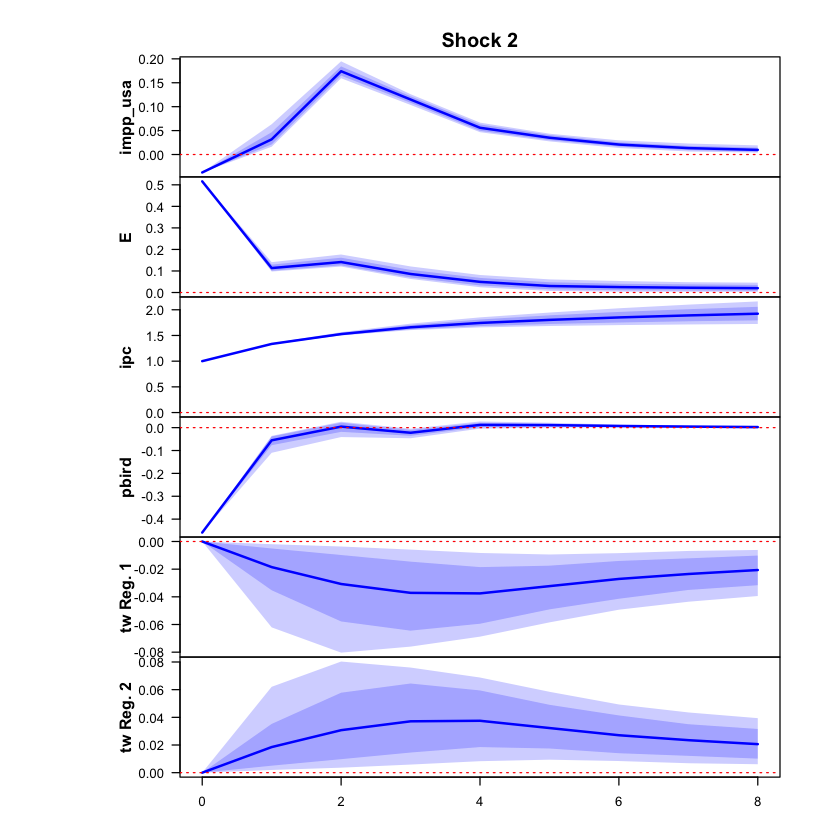

 >>> Linear IRF ( 1  shock units)


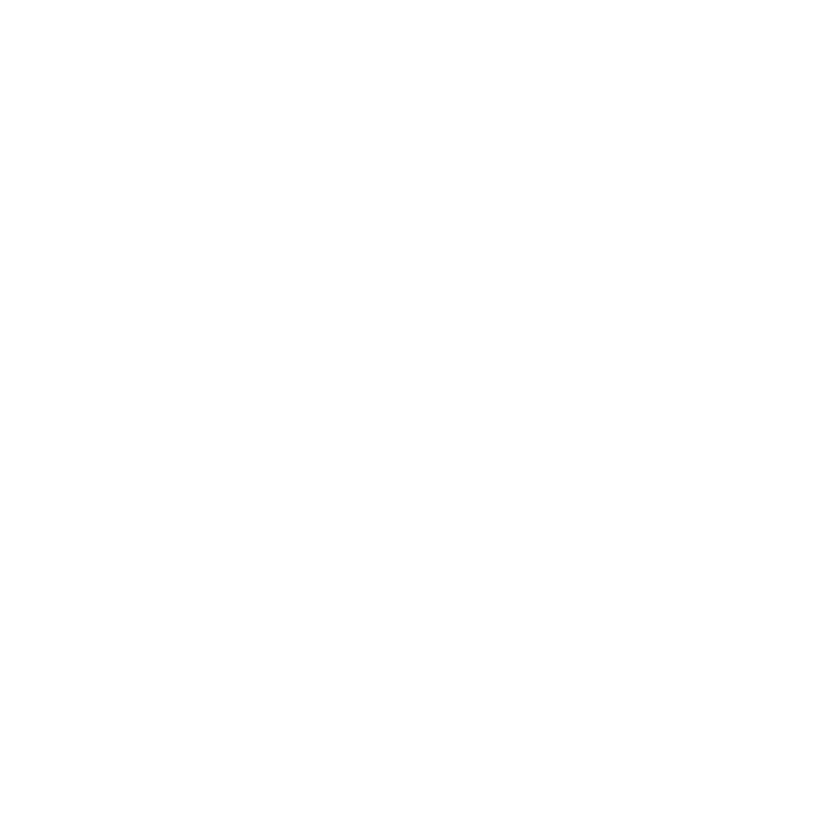

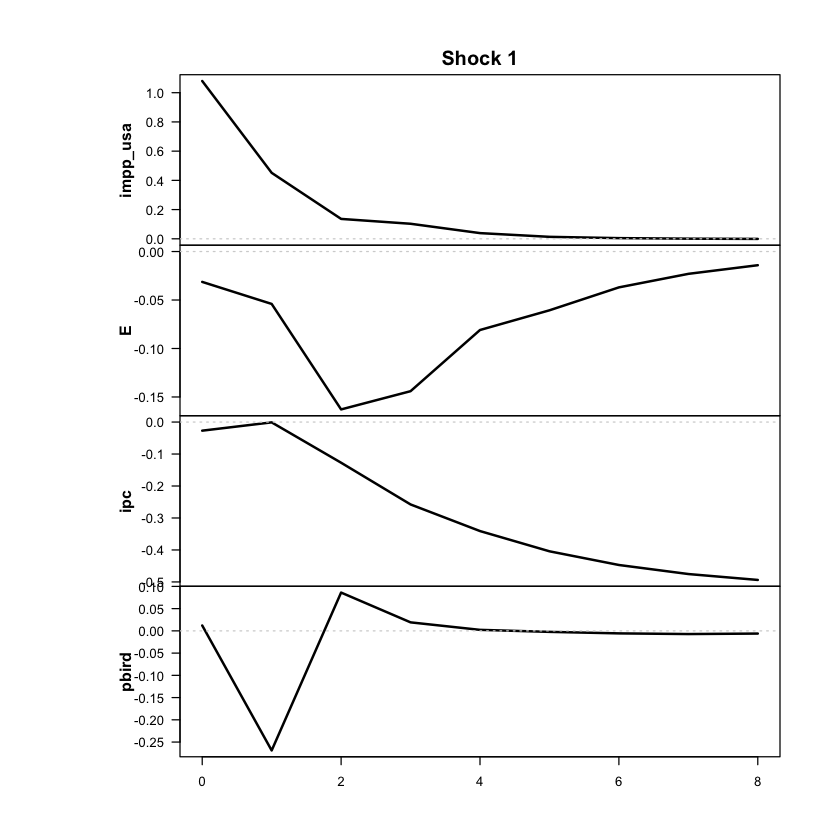

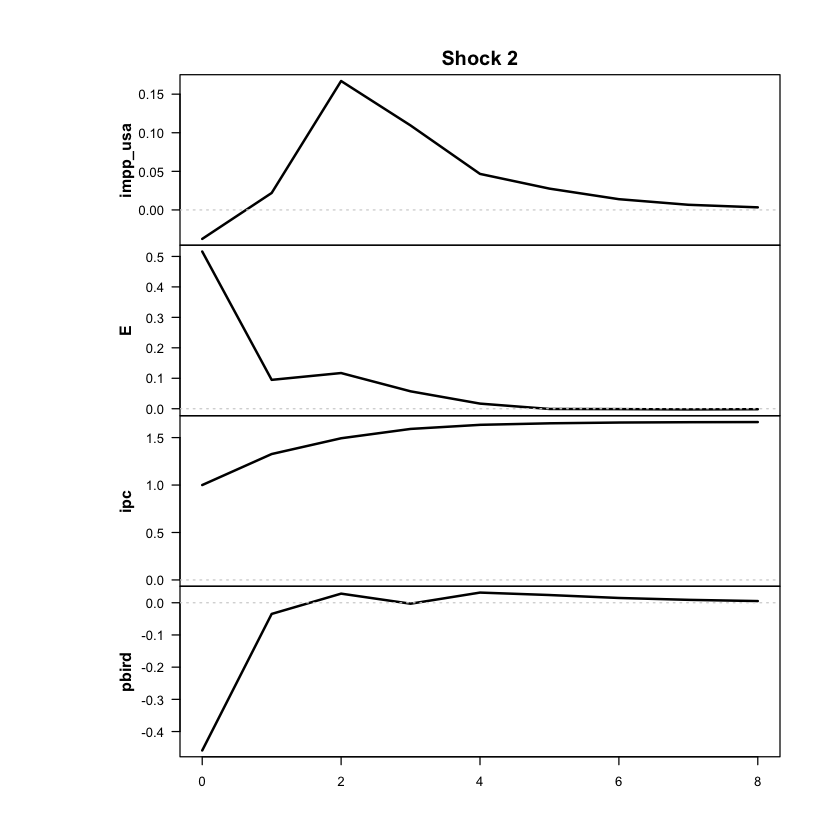

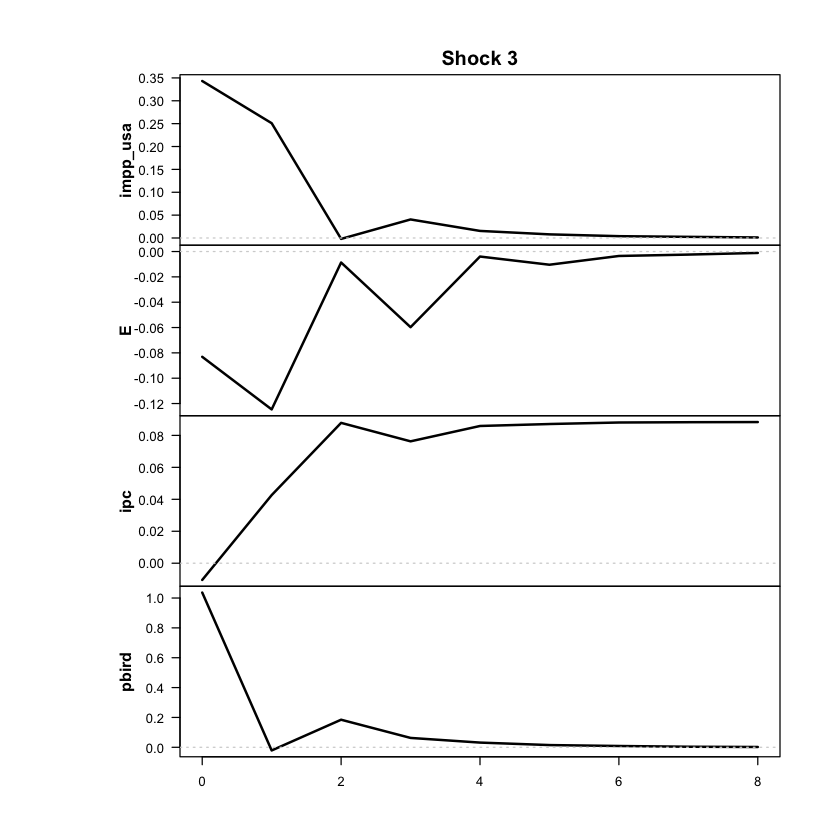

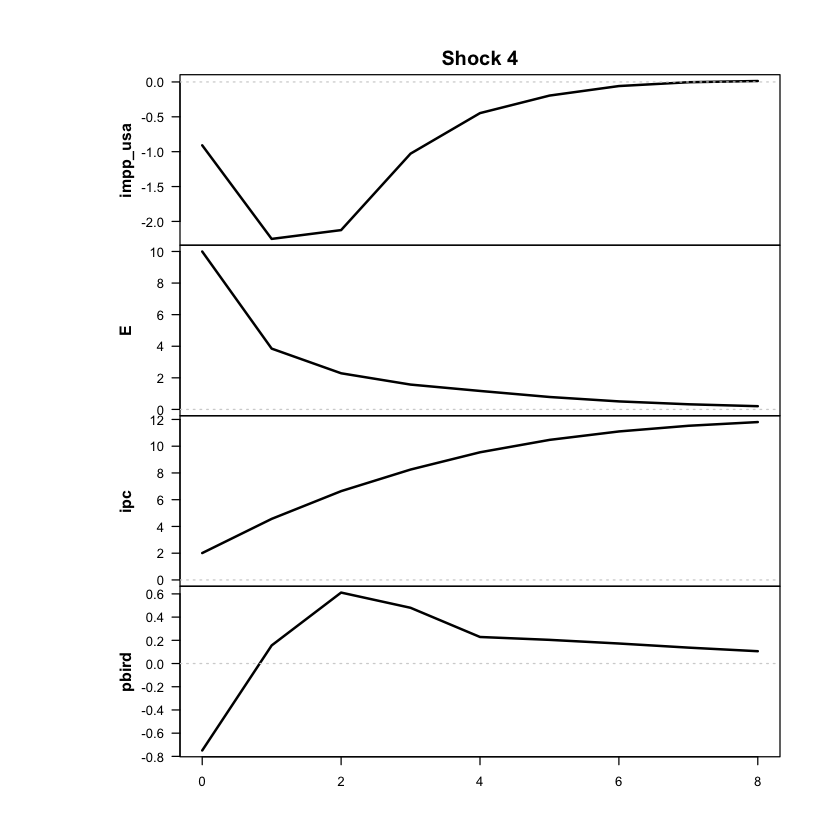

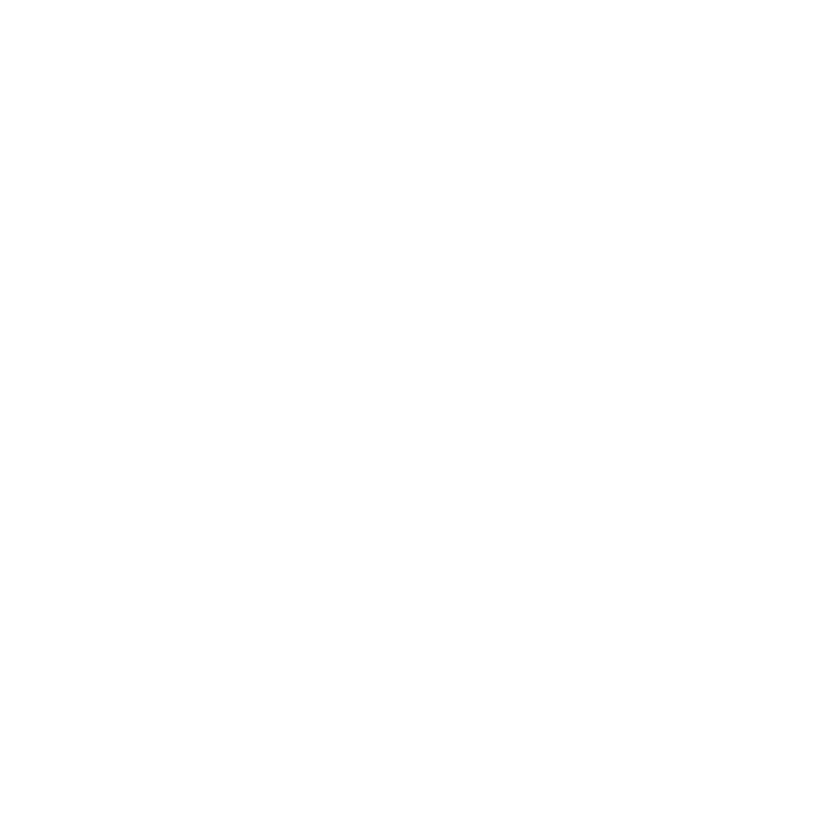

In [20]:
res <- run_vlstar(
  data = df_ERPT_Arg,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral',
  feature_lag = 2,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc',
  thr_lag = 1,
  shock_var = 'E',
  response_vars = c('ipc'),
  run_tests = FALSE,
  irf_horizons = NULL,
  irf_shocks = 1,
  diagnostic_plots = TRUE,
  nrounds = 500,
  load_presaved = FALSE,
  cond_dist = "ind_Student",       # shocks t de Student independientes
  estim_method = "three-phase"     # recomendado para estos modelos (Virolainen)
)

In [22]:
ic_vlstar_indt_p2 <- criterios_info(res, "VLSTAR-indt p=2")
print(ic_vlstar_indt_p2)

           modelo regimenes parametros  loglik    AIC     HQ    BIC
1 VLSTAR-indt p=2         2        110 -523.97 1267.9 1430.1 1672.7


In [23]:
resumen_modelo(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"))
# Con ind_Student muestra "errores: ind_Student".

Modelo: logistic | regímenes: 2 | rezagos: 2 | errores: ind_Student 
Umbral (c): 14.2 % trimestral ( 70 % anualizada) | gamma: 4.99 
Trimestres por régimen (régimen de mayor peso): régimen 1 = 214 | régimen 2 = 79 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      0.59      1.19
E             4.02     37.62
ipc           5.12     39.12
pbird         0.76     -0.06


In [24]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -523.69            37.5  1.89         NA           267/26
             2 -523.97            14.2  4.99         NA           214/79
             3 -525.81            26.4  2.38         NA           246/47
             4 -526.35            27.1  2.47         NA           246/47
             5 -526.89            29.4  2.30         NA           255/38
             6 -526.95            29.9  2.34         NA           255/38
             7 -527.22            27.6  2.32         NA           249/44
             8 -527.23            29.6  2.13         NA           255/38
             9 -527

In [25]:
print(res$tvar_model)   # avisos y grados de libertad de cada shock (uno por variable)

logistic ind_Student STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 2, M = 2, d = 4, #parameters = 110, #observations = 293 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Degrees of freedom: 2.36, 2.02, 3.43, 2.01 (for all regimes) 
Weight params: 0.67 (location), 4.99 (scale) 
Regime means:  0.23, -0.05,  0.00,  0.50

   Y      phi0          A1                                 A2                  
1 y1 = [  0.09 ] + [  0.46  0.09 -0.29  0.01 ] y1.1 + [  0.09 -0.04  0.03  0.03
2 y2   [ -0.02 ]   [  0.00  0.62 -0.08  0.00 ] y2.1   [  0.00 -0.02  0.00  0.00
3 y3   [  0.00 ]   [  0.00  0.20  0.33  0.02 ] y3.1   [  0.01  0.00  0.17 -0.01
4 y4   [  0.37 ]   [  0.10 -0.35 -0.22  0.22 ] y4.1   [  0.01 -0.04  0.16 -0.06
                 B                         
1 ] y1.2 + [  1.04  0.13  0.07  0.03 ] eps1
2 ] y2.2   [  0.00 -0.05  0.00 -0.24 ] eps2
3 ] y3.2   [  0.02  0.42  0.02 -0.09 ] eps3
4 ] y4.2   [ -0.01 -0.81  0.86  0.05 ] eps4

Regime 2 
Regime me

In [26]:
shock_vlstar_indt_p2 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Revisar que el MISMO shock concentre el efecto sobre E en los dos regímenes.
# Si aparece el aviso "!!! ATENCIÓN", no seguir: hay que reordenar las columnas de B.
shock_vlstar_indt_p2

Efecto de impacto de cada shock (régimen 1) (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0287  0.0036  0.0019  0.0008
  E         0.0006 -0.0113  0.0006 -0.0577
  ipc       0.0039  0.0834  0.0035 -0.0178
  pbird    -0.0003 -0.0226  0.0238  0.0013

Participación de E en el efecto de cada shock (régimen 1) :
shock_1 shock_2 shock_3 shock_4 
   0.00    0.05    0.00    0.92 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  7.021  -7.383   6.349   0.309 

--- Régimen 2 ---
Efecto de impacto (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0298 -0.0032  0.0095 -0.0251
  E        -0.0075  0.3760 -0.0199  2.3919
  ipc      -0.0053  0.6047 -0.0021  0.3991
  pbird     0.0003 -0.0388  0.0288 -0.0208
Participación de E :
shock_1 shock_2 shock_3 shock_4 
   0.03    0.42    0.08    0.97 
ERPT de impacto:
shock_1 shock_2 shock_3 shock_4 
  0.714   1.608   0.105   0.167 

El mism

[1] 4

In [28]:
alt_signo <- fitSSTVAR(res$tvar_model, identification = "non-Gaussianity",
                       B_pm_reg = 2, B_perm = 1:4, B_signs = c(1, 1, 1, -1))
print(alt_signo)

ERROR: Error in fitSSTVAR(res$tvar_model, identification = "non-Gaussianity", : B_signs should only contain integers between 1 and d


In [29]:
?fitSSTVAR

fitSSTVAR               package:sstvars                R Documentation

_M_a_x_i_m_u_m _l_i_k_e_l_i_h_o_o_d _e_s_t_i_m_a_t_i_o_n _o_f _a _s_t_r_u_c_t_u_r_a_l _S_T_V_A_R _m_o_d_e_l _b_a_s_e_d _o_n
_p_r_e_l_i_m_i_n_a_r_y _e_s_t_i_m_a_t_e_s _f_r_o_m _a _r_e_d_u_c_e_d _f_o_r_m _m_o_d_e_l.

_D_e_s_c_r_i_p_t_i_o_n:

     ‘fitSSTVAR’ uses a robust method and a variable metric algorithm
     to estimate a structural STVAR model based on preliminary
     estimates from a reduced form model.

_U_s_a_g_e:

     fitSSTVAR(
       stvar,
       identification = c("recursive", "heteroskedasticity", "non-Gaussianity"),
       B_constraints = NULL,
       B_pm_reg = NULL,
       B_perm = NULL,
       B_signs = NULL,
       maxit = 1000,
       maxit_robust = 1000,
       h = 0.001,
       robust_method = c("Nelder-Mead", "SANN", "none"),
       print_res = TRUE,
       calc_std_errors = TR

In [30]:
alt_signo <- fitSSTVAR(res$fit_struct, identification = "non-Gaussianity",
                       B_pm_reg = 2, B_signs = 4)

The log-likelihood of the supplied model:    -523.965
Constrained log-likelihood prior estimation: -584.299

The log-likelihood after robust estimation:  -567.627

The log-likelihood after final estimation:   -527.386

Calculating approximate standard errors...



In [31]:
cat("Log-verosimilitud original:   ", res$fit_struct$loglik, "\n")
cat("Log-verosimilitud con el signo cambiado:", alt_signo$loglik, "\n")

Log-verosimilitud original:    -523.9653 
Log-verosimilitud con el signo cambiado: -527.3864 


In [32]:
identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"), modelo = alt_signo)

Efecto de impacto de cada shock (régimen 1) (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0282  0.0050  0.0019 -0.0025
  E         0.0024 -0.0186  0.0010  0.0395
  ipc       0.0029  0.0617  0.0042  0.0095
  pbird    -0.0011 -0.0216  0.0245  0.0027

Participación de E en el efecto de cada shock (régimen 1) :
shock_1 shock_2 shock_3 shock_4 
   0.01    0.09    0.00    0.76 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  1.233  -3.321   4.422   0.241 

--- Régimen 2 ---
Efecto de impacto (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0300 -0.0038  0.0097  0.0266
  E        -0.0303  0.4081 -0.0153 -2.3928
  ipc      -0.0123  0.6026  0.0034 -0.3938
  pbird     0.0002 -0.0380  0.0289  0.0213
Participación de E :
shock_1 shock_2 shock_3 shock_4 
   0.12    0.46    0.06    0.97 
ERPT de impacto:
shock_1 shock_2 shock_3 shock_4 
  0.406   1.477  -0.220   0.165 

!!! ATE

### ERPT — VLSTAR con shocks t independientes (solo si pasó el diagnóstico)

In [ ]:
out_impp_usa_vlstar_indt_p2 <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_vlstar_indt_p2, deprec_pct = 8)

In [ ]:
out_impp_usa_vlstar_indt_p2_acum <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_vlstar_indt_p2,
                      definicion = "acumulado", deprec_pct = 8)

In [ ]:
graficar_transicion(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_vlstar_indt_p2_sincap")

In [ ]:
graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_vlstar_indt_p2,
                       archivo = "girf_original_impp_usa_vlstar_indt_p2_sincap")

## Comparación de criterios

Con el TVAR principal gaussiano (loglik −896,09, AIC 1978,2, HQ 2115,3, BIC 2320,4) y el TVAR-t (−681,36, 1550,7, 1689,3, 1896,7). Todos con los mismos datos, así que son comparables.

In [33]:
rbind(ic_tvar_indt_p2, ic_vlstar_indt_p2)

modelo,regimenes,parametros,loglik,AIC,HQ,BIC
<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
TVAR-indt p=2,2,109,-615.43,1448.9,1609.5,1850.0
VLSTAR-indt p=2,2,110,-523.97,1267.9,1430.1,1672.7


# Test de Portmanteau (todos los modelos sin cappeo con impp_usa)

In [34]:
portmanteau_guardados <- function(data, rezagos_test = c(8, 12), carpeta = "models") {
  archivos <- list.files(carpeta, pattern = "\\.rds$", full.names = TRUE)
  archivos <- archivos[!grepl("^structured_", basename(archivos))]
  pval <- function(t) {
    nm <- grep("p_val|pval|p.val", names(t), value = TRUE)
    if (length(nm)) as.numeric(t[[nm[1]]]) else NA
  }
  etiqueta <- function(m) {
    wf <- m$model$weight_function
    tipo <- switch(if (is.null(wf)) "" else wf,
                   threshold = "TVAR", logistic = "VLSTAR", mlogit = "MLOGIT", "?")
    cd <- m$model$cond_dist
    if (!is.null(cd) && cd == "Student") tipo <- paste0(tipo, "-t")
    if (!is.null(cd) && cd == "ind_Student") tipo <- paste0(tipo, "-indt")
    tipo
  }
  filas <- list()
  for (f in archivos) {
    m <- tryCatch(readRDS(f), error = function(e) NULL)
    if (is.null(m) || is.null(m$data) || is.null(m$model)) next
    Y <- as.matrix(m$data); vars <- colnames(Y)
    if (!all(vars %in% names(data)) || nrow(data) != nrow(Y)) next
    X <- as.matrix(data[, vars]); X <- sweep(X, 2, apply(X, 2, sd, na.rm = TRUE), "/")
    if (!isTRUE(all.equal(unname(X), unname(Y), tolerance = 1e-6))) next
    for (L in rezagos_test) {
      ac <- tryCatch(Portmanteau_test(m, nlags = L, which_test = "autocorr"), error = function(e) NULL)
      hs <- tryCatch(Portmanteau_test(m, nlags = L, which_test = "het.sked"), error = function(e) NULL)
      filas[[length(filas) + 1]] <- data.frame(
        commodity = vars[1],
        modelo    = etiqueta(m),
        regimenes = m$model$M, rezagos = m$model$p, rezagos_test = L,
        p_autocorr = round(if (is.null(ac)) NA else pval(ac), 3),
        p_heterosc = round(if (is.null(hs)) NA else pval(hs), 3))
    }
  }
  tab <- do.call(rbind, filas)
  tab <- tab[order(tab$commodity, tab$modelo, tab$regimenes, tab$rezagos, tab$rezagos_test), ]
  print(tab, row.names = FALSE)
  invisible(tab)
}

# Solo los modelos con impp_usa (los viejos de commodities quedan afuera)
port_sincap <- portmanteau_guardados(df_ERPT_Arg)
port_impp <- port_sincap[port_sincap$commodity == "impp_usa", ]
print(port_impp, row.names = FALSE)

  commodity      modelo regimenes rezagos rezagos_test p_autocorr p_heterosc
   impp_usa      MLOGIT         3       2            8      0.000      0.000
   impp_usa      MLOGIT         3       2           12      0.005      0.007
   impp_usa      MLOGIT         3       3            8      0.000      0.000
   impp_usa      MLOGIT         3       3           12      0.008      0.000
   impp_usa        TVAR         2       2            8      0.008      0.000
   impp_usa        TVAR         2       2           12      0.123      0.000
   impp_usa        TVAR         2       3            8      0.023      0.000
   impp_usa        TVAR         2       3           12      0.304      0.000
   impp_usa        TVAR         3       2            8      0.017      0.000
   impp_usa        TVAR         3       2           12      0.011      0.001
   impp_usa        TVAR         3       3            8      0.028      0.000
   impp_usa        TVAR         3       3           12      0.083      0.008